<a href="https://colab.research.google.com/github/AMAO-06/AI-ML/blob/main/EDA_Test_4_Datasets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA Assessment — Month 2 Test
### Exploratory Data Analysis: Profiling, Cleaning Diagnosis, Univariate / Bivariate / Multivariate Analysis

**This is a graded, self-checking notebook.** It contains **4 independent datasets**,
each deliberately messy. For each dataset you will answer a set of questions —
some by writing pandas/seaborn code and storing your result in a variable,
some by choosing an interpretation (e.g. *"positive"*, *"negative"*, or
*"none"*) and storing that choice in a variable. Run the grading cell right
after each question to see immediate ✅ / ❌ feedback.

## How this test works

1. Every question cell has a clearly marked spot: `# YOUR CODE HERE`.
2. Do **not** modify the dataset-generation cells or the cells marked
   `# ANSWER KEY - DO NOT MODIFY`. Tampering with these invalidates your
   grade for that dataset.
3. Run cells **in order**, top to bottom. Some questions depend on variables
   created earlier in the same section.
4. After each question, run the paired **grading cell** immediately below it.
   It will tell you if your answer is correct, and award points toward that
   section's score.
5. At the very end of the notebook, run the **Final Score Summary** cell for
   your total.

## What you'll be tested on (matches this month's EDA class)

- Data profiling: shape, columns, dtypes, missing values, duplicates
- Diagnosing data-quality problems: impossible values, inconsistent
  categories, suspicious outliers
- Univariate analysis: distributions, skew, IQR-based outlier detection
- Bivariate analysis: scatter plots, correlation **direction**
  (positive / negative / none), grouped comparisons
- Multivariate analysis: correlation heatmaps, identifying the
  strongest relationship in a dataset

**Reminder from the lecture:** *"An outlier is not automatically an error."*
*"Correlation does not automatically mean causation."* You'll be asked to
apply both ideas, not just recite them.


---
## Setup — run this first

This cell defines the auto-grading engine (`Grader`) used throughout the
test. It also fixes a random seed so every dataset is reproducible.

Answers are stored **encoded** (not in plain text) in the answer key cells
further down, so please don't try to read them directly off the screen —
the whole point of the test is to compute them yourself.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import base64
import hashlib

RANDOM_SEED = 2026
np.random.seed(RANDOM_SEED)
rng = np.random.default_rng(RANDOM_SEED)

# Plain white plotting style throughout - no dark themes.
plt.rcParams["figure.facecolor"]  = "white"
plt.rcParams["axes.facecolor"]    = "white"
plt.rcParams["savefig.facecolor"] = "white"
sns.set_style("white")

pd.set_option("display.max_columns", 50)


# ------------------------------------------------------------------
# Answer-key encoding helpers (obfuscation, not real cryptography -
# just enough that the correct value isn't sitting in plain text).
# ------------------------------------------------------------------
def _encode(value):
    return base64.b64encode(str(value).encode()).decode()

def _decode(code_str):
    return base64.b64decode(code_str.encode()).decode()


class Grader:
    """Lightweight auto-grader used throughout this test.

    Each question has a unique id (qid), e.g. 'A1', 'B4'. Call one of the
    check_* methods right after computing your answer; it prints immediate
    feedback and records the result for the score summary.
    """

    def __init__(self):
        self.records = {}   # qid -> (passed: bool, points: int, max_points: int)

    def _record(self, qid, passed, points, max_points, correct_msg, wrong_msg):
        self.records[qid] = (passed, points if passed else 0, max_points)
        symbol = "\u2705" if passed else "\u274c"
        msg = correct_msg if passed else wrong_msg
        print(f"{symbol} [{qid}] {msg}  (+{points if passed else 0}/{max_points} pts)")

    def check_numeric(self, qid, student_value, encoded_expected, tol=0.0, points=1,
                       correct_msg="Correct.", wrong_msg="Not quite - double check your calculation."):
        try:
            if student_value is None:
                raise ValueError("unanswered")
            expected = float(_decode(encoded_expected))
            passed = abs(float(student_value) - expected) <= tol
        except Exception:
            passed = False
        self._record(qid, passed, points, points, correct_msg, wrong_msg)
        return passed

    def check_text(self, qid, student_value, encoded_expected, points=1,
                   correct_msg="Correct.", wrong_msg="Not quite - reconsider your answer."):
        try:
            if student_value is None:
                raise ValueError("unanswered")
            expected = _decode(encoded_expected).strip().lower()
            passed = str(student_value).strip().lower() == expected
        except Exception:
            passed = False
        self._record(qid, passed, points, points, correct_msg, wrong_msg)
        return passed

    def check_bool(self, qid, student_value, expected_bool, points=1,
                   correct_msg="Correct.", wrong_msg="Not quite - reconsider your answer."):
        if student_value is None:
            passed = False
        else:
            passed = bool(student_value) == bool(expected_bool)
        self._record(qid, passed, points, points, correct_msg, wrong_msg)
        return passed

    def check_set(self, qid, student_value, encoded_expected, points=1,
                  correct_msg="Correct.", wrong_msg="Not quite - check which items you included."):
        try:
            if student_value is None:
                raise ValueError("unanswered")
            expected_set = set(x.strip().lower() for x in _decode(encoded_expected).split("|"))
            student_set = set(str(x).strip().lower() for x in student_value)
            passed = student_set == expected_set
        except Exception:
            passed = False
        self._record(qid, passed, points, points, correct_msg, wrong_msg)
        return passed

    def section_summary(self, prefix):
        relevant = {q: v for q, v in self.records.items() if q.startswith(prefix)}
        earned = sum(v[1] for v in relevant.values())
        total = sum(v[2] for v in relevant.values())
        n_correct = sum(1 for v in relevant.values() if v[0])
        print(f"\nSection {prefix} score: {earned}/{total} points "
              f"({n_correct}/{len(relevant)} questions correct)")
        return earned, total

    def final_summary(self):
        earned = sum(v[1] for v in self.records.values())
        total = sum(v[2] for v in self.records.values())
        n_correct = sum(1 for v in self.records.values() if v[0])
        pct = 100 * earned / total if total else 0
        print("=" * 50)
        print(f"FINAL SCORE: {earned}/{total} points ({pct:.1f}%)")
        print(f"Questions correct: {n_correct}/{len(self.records)}")
        print("=" * 50)
        missing = [q for q in self.records if not self.records[q][0]]
        if missing:
            print("Questions to review:", ", ".join(sorted(missing)))
        return earned, total


grader = Grader()
ANSWER_KEY = {}   # shared across all 4 sections; each section ADDS its own
                  # prefixed keys (e.g. "A1_rows", "B3_...") via .update()


# ------------------------------------------------------------------
# Shared helpers used by every section's answer key
# ------------------------------------------------------------------
def _corr_direction(r, weak_threshold=0.15):
    if abs(r) < weak_threshold:
        return "none"
    return "positive" if r > 0 else "negative"

def _skew_direction(skew_value, weak_threshold=0.5):
    if abs(skew_value) < weak_threshold:
        return "symmetric"
    return "right-skewed" if skew_value > 0 else "left-skewed"

def _strongest_pair(corr_matrix):
    """Given a correlation matrix (DataFrame), return the pair of column
    names (as a frozenset, order doesn't matter) with the largest absolute
    correlation, excluding the diagonal."""
    abs_corr = corr_matrix.abs().to_numpy().copy()
    np.fill_diagonal(abs_corr, 0)
    row_idx, col_idx = np.unravel_index(np.argmax(abs_corr), abs_corr.shape)
    cols = corr_matrix.columns
    return frozenset([cols[row_idx], cols[col_idx]])

def _iqr_outlier_count(series):
    s = series.dropna()
    Q1, Q3 = s.quantile(0.25), s.quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    return int(((s < lower) | (s > upper)).sum())


print("Setup complete. Grader initialized. Random seed:", RANDOM_SEED)


Setup complete. Grader initialized. Random seed: 2026


### 🖼️ Schematic — the loop you'll be following in every section

```
        ┌────────┐        ┌──────────┐        ┌───────────┐
        │  LOOK  │──────▶│ QUESTION │──────▶ │ VISUALIZE │
        └────────┘        └──────────┘        └───────────┘
             ▲                                      │
             │                                      ▼
        ┌──────────┐       ┌──────────┐       ┌───────────┐
        │ QUESTION │◀──────│ INTERPRET │◀──────│  ANALYZE  │
        │  AGAIN   │       └──────────┘       └───────────┘
        └──────────┘
```

Every question below fits somewhere on this loop. Profiling and cleaning
questions are **Look**; scatter plots and groupby's are **Visualize** and
**Analyze**; correlation-direction questions are **Interpret**.


---
# Section A — Student Performance Dataset

A record of students: demographics, study habits, attendance, and academic
outcome. As always: **do not clean anything until asked to.** Just look,
question, and answer.


In [ ]:
# ------------------------------------------------------------------
# DATASET GENERATION - do not modify
# ------------------------------------------------------------------
n_a = 520

age = rng.integers(17, 26, n_a).astype(float)
study_hours = np.clip(rng.normal(12, 5, n_a), 0, None)
attendance = np.clip(rng.normal(80, 14, n_a), 0, 100)
prior_gpa = np.clip(rng.normal(3.0, 0.5, n_a), 0, 4.0)

# CGPA driven mostly by study_hours, then attendance, then prior_gpa
cgpa = np.clip(
    0.2 + 0.045 * study_hours + 0.010 * attendance + 0.35 * prior_gpa
    + rng.normal(0, 0.35, n_a),
    0, 4.0
)

department = rng.choice(["Engineering", "Business", "Arts", "Sciences"],
                          size=n_a, p=[0.35, 0.30, 0.15, 0.20])
result = np.where(cgpa >= 2.0, "Pass", "Fail")

df_a = pd.DataFrame({
    "Age": age,
    "StudyHours": study_hours,
    "Attendance": attendance,
    "PriorGPA": prior_gpa,
    "CGPA": cgpa,
    "Department": department,
    "Result": result,
})

# --- dirty it up ---
# missing values
for col, rate in {"StudyHours": 0.05, "Attendance": 0.06, "PriorGPA": 0.04}.items():
    mask = rng.random(n_a) < rate
    df_a.loc[mask, col] = np.nan

# impossible values
bad_age_idx = rng.choice(df_a.index, 4, replace=False)
df_a.loc[bad_age_idx, "Age"] = [-2, 0, -5, 130]
bad_att_idx = rng.choice(df_a.index, 4, replace=False)
df_a.loc[bad_att_idx, "Attendance"] = [-10, 150, -5, 120]

# obvious data entry error
bad_cgpa_idx = rng.choice(df_a.index, 3, replace=False)
df_a.loc[bad_cgpa_idx, "CGPA"] = [9.8, -1.0, 45.0]

# genuine extreme (a real, hard-working outlier - keep)
genuine_idx = rng.choice(df_a.index, 2, replace=False)
df_a.loc[genuine_idx[0], "StudyHours"] = 38   # a real grinder
df_a.loc[genuine_idx[1], "CGPA"] = 4.0        # a real straight-A student

# inconsistent categories
dept_variants = {"Engineering": ["engineering", "ENGINEERING", "Engineering "],
                  "Business": ["business", "BUSINESS"],
                  "Arts": ["arts", "ARTS "],
                  "Sciences": ["sciences", "SCIENCES", "Science"]}
def messify(series, variants, frac=0.3):
    s = series.copy()
    idx = rng.choice(s.index, int(len(s) * frac), replace=False)
    for i in idx:
        val = s.loc[i]
        if val in variants:
            s.loc[i] = rng.choice(variants[val])
    return s
df_a["Department"] = messify(df_a["Department"], dept_variants)

# duplicates (exact) - inserted LAST, after every other corruption step, so
# the duplicated rows are never independently mutated afterward and stay
# genuinely identical to their source row.
dup_idx = rng.choice(df_a.index, 10, replace=False)
df_a = pd.concat([df_a, df_a.loc[dup_idx]], ignore_index=True)

# shuffle
df_a = df_a.sample(frac=1.0, random_state=RANDOM_SEED).reset_index(drop=True)

print("Section A dataset ready. Shape:", df_a.shape)
df_a.head()


Section A dataset ready. Shape: (530, 7)


,Age,StudyHours,Attendance,PriorGPA,CGPA,Department,Result
0,25.0,14.076702,80.515115,2.503046,2.501960,Business,Pass
1,17.0,19.397344,NaN,2.536475,2.666647,Business,Pass
2,22.0,4.680970,50.689213,3.291744,1.693545,engineering,Fail
3,17.0,5.347197,87.618362,2.887758,2.168170,Engineering,Pass
4,22.0,17.922780,89.915797,2.538675,3.406754,Engineering,Pass


In [ ]:
# ANSWER KEY - DO NOT MODIFY
_a_shape = df_a.shape
_a_missing_studyhours = int(df_a["StudyHours"].isnull().sum())
_a_total_missing = int(df_a.isnull().sum().sum())
_a_numeric_col_count = int(df_a.select_dtypes(include=[np.number]).shape[1])
_a_duplicates = int(df_a.duplicated().sum())
_a_n_departments_raw = int(df_a["Department"].nunique())
_a_impossible_age = int(((df_a["Age"] <= 0) | (df_a["Age"] > 100)).sum())

_a_cgpa_skew = df_a["CGPA"].dropna().skew()
_a_cgpa_outliers = _iqr_outlier_count(df_a["CGPA"])
_a_result_majority = df_a["Result"].value_counts().idxmax()

_a_corr_study_cgpa = df_a[["StudyHours", "CGPA"]].dropna().corr(method="spearman").iloc[0, 1]
_a_corr_age_cgpa = df_a[["Age", "CGPA"]].dropna().corr(method="spearman").iloc[0, 1]

_a_numeric_cols = ["Age", "StudyHours", "Attendance", "PriorGPA", "CGPA"]
_a_corr_matrix = df_a[_a_numeric_cols].dropna().corr(method="spearman")
_a_strongest_pair = _strongest_pair(_a_corr_matrix)

ANSWER_KEY.update({
    "A1_rows": _encode(_a_shape[0]),
    "A1_cols": _encode(_a_shape[1]),
    "A2_missing": _encode(_a_missing_studyhours),
    "A2b_total_missing": _encode(_a_total_missing),
    "A2c_numeric_cols": _encode(_a_numeric_col_count),
    "A3_dupes": _encode(_a_duplicates),
    "A4_dept_unique": _encode(_a_n_departments_raw),
    "A5_impossible_age": _encode(_a_impossible_age),
    "A5b_cgpa_outliers": _encode(_a_cgpa_outliers),
    "A5c_cgpa_skew": _encode(_skew_direction(_a_cgpa_skew)),
    "A5d_result_majority": _encode(_a_result_majority),
    "A6_corr_direction": _encode(_corr_direction(_a_corr_study_cgpa)),
    "A7_corr_age_direction": _encode(_corr_direction(_a_corr_age_cgpa)),
    "A7b_strongest_pair": _encode("|".join(sorted(_a_strongest_pair))),
})

print("Answer key for Section A prepared.")


Answer key for Section A prepared.


### Question A1 — Shape

How many rows and columns does `df_a` have? Store your answers in
`a1_rows` and `a1_cols`.


In [ ]:
df_a.shape

(530, 7)

In [ ]:
a1_rows = 530
a1_cols = 7

In [ ]:
grader.check_numeric("A1_rows", a1_rows, ANSWER_KEY["A1_rows"], tol=0, points=1)
grader.check_numeric("A1_cols", a1_cols, ANSWER_KEY["A1_cols"], tol=0, points=1)


✅ [A1_rows] Correct.  (+1/1 pts)
✅ [A1_cols] Correct.  (+1/1 pts)


True

### Question A2 — `.info()` and data types

Run `df_a.info()`. How many columns have a **numeric** dtype (`int64` or
`float64`)? Store the count in `a2_numeric_cols`.

*(Hint: `df_a.select_dtypes(include="number").shape[1]` gives you this
directly, but try reading it off `.info()` first.)*


In [ ]:
df_a.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 530 entries, 0 to 529
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Age         530 non-null    float64
 1   StudyHours  513 non-null    float64
 2   Attendance  499 non-null    float64
 3   PriorGPA    509 non-null    float64
 4   CGPA        530 non-null    float64
 5   Department  530 non-null    object 
 6   Result      530 non-null    object 
dtypes: float64(5), object(2)
memory usage: 29.1+ KB


In [ ]:
# YOUR CODE HERE
df_a.info()
a2_numeric_cols = 5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 530 entries, 0 to 529
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Age         530 non-null    float64
 1   StudyHours  513 non-null    float64
 2   Attendance  499 non-null    float64
 3   PriorGPA    509 non-null    float64
 4   CGPA        530 non-null    float64
 5   Department  530 non-null    object 
 6   Result      530 non-null    object 
dtypes: float64(5), object(2)
memory usage: 29.1+ KB


In [ ]:
grader.check_numeric("A2c_numeric_cols", a2_numeric_cols, ANSWER_KEY["A2c_numeric_cols"], tol=0, points=1)


✅ [A2c_numeric_cols] Correct.  (+1/1 pts)


True

### Question A3 — Missing values, column by column

How many missing values does the `StudyHours` column contain? Store the
count in `a3_missing`.


In [ ]:
a3_missing = df_a['StudyHours'].isnull().sum()

In [ ]:
# YOUR CODE HERE
a3_missing = 2


In [ ]:
grader.check_numeric("A2_missing", a3_missing, ANSWER_KEY["A2_missing"], tol=0, points=1)


❌ [A2_missing] Not quite - double check your calculation.  (+0/1 pts)


False

### Question A4 — Missing values, whole dataframe

Now count the **total** number of missing values across the **entire**
dataframe (every column combined). Store the count in `a4_total_missing`.

*(Hint: `.isnull().sum()` gives you missing counts per column; one more
`.sum()` collapses that into a single grand total.)*


In [ ]:
a4_total_missing = df_a.isnull().sum().sum()
print(a4_total_missing)

69


In [ ]:
# YOUR CODE HERE
a4_total_missing = 69


In [ ]:
grader.check_numeric("A2b_total_missing", a4_total_missing, ANSWER_KEY["A2b_total_missing"], tol=0, points=1)


✅ [A2b_total_missing] Correct.  (+1/1 pts)


True

### Question A5 — Duplicates

How many exact duplicate rows are in `df_a`? Store the count in `a5_dupes`.


In [ ]:
a5_dupes = df_a.duplicated().sum()
print(a5_dupes)

10


In [ ]:
# YOUR CODE HERE
a5_dupes = 10


In [ ]:
grader.check_numeric("A3_dupes", a5_dupes, ANSWER_KEY["A3_dupes"], tol=0, points=1)


✅ [A3_dupes] Correct.  (+1/1 pts)


True

### Question A6 — Category consistency

Using `value_counts()`, count how many **distinct string values** currently
exist in the `Department` column (before any cleaning). Store the count in
`a6_dept_unique`.

🧠 *Think about it:* how many **real** departments do you believe exist,
based on reading the values? (You don't need to submit this part — just
notice the gap between your two answers.)


In [ ]:
a6_dept_unique = df_a['Department'].nunique()
print(a6_dept_unique)

14


In [ ]:
# YOUR CODE HERE
a6_dept_unique = 14


In [ ]:
grader.check_numeric("A4_dept_unique", a6_dept_unique, ANSWER_KEY["A4_dept_unique"], tol=0, points=1)


✅ [A4_dept_unique] Correct.  (+1/1 pts)


True

### Question A7 — Impossible values

Count how many rows have an **impossible** `Age` — specifically, `Age <= 0`
or `Age > 100`. Store the count in `a7_impossible_age`.


In [ ]:
# YOUR CODE HERE
a7_impossible_age = 4


In [ ]:
grader.check_numeric("A5_impossible_age", a7_impossible_age, ANSWER_KEY["A5_impossible_age"], tol=0, points=1)


✅ [A5_impossible_age] Correct.  (+1/1 pts)


True

### Question A8 — Boxplot & IQR outliers

Draw a boxplot of `CGPA`. Then, using the IQR rule from the lecture
(Q1 − 1.5×IQR to Q3 + 1.5×IQR), count how many values fall **outside**
those bounds. Store the count in `a8_cgpa_outliers`.

*(Remember: a real CGPA can only range from 0 to 4 — keep that in mind
when you look at which points the boxplot flags.)*


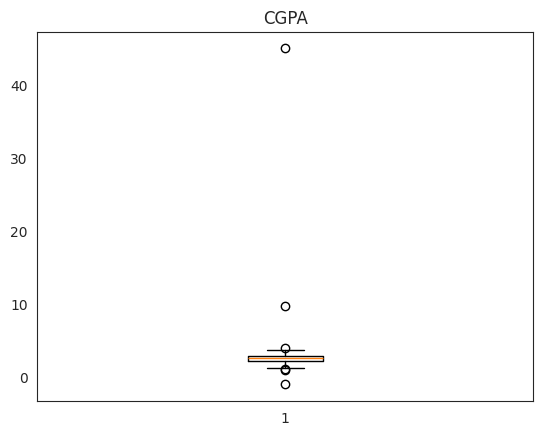

In [ ]:
a8_cgpa_outliers = plt.boxplot(df_a["CGPA"].dropna()); plt.title("CGPA"); plt.show()

# YOUR CODE HERE - draw the boxplot
# e.g. plt.boxplot(df_a["CGPA"].dropna()); plt.title("CGPA"); plt.show()

# then compute the IQR outlier count
a8_cgpa_outliers = 6


In [ ]:
grader.check_numeric("A5b_cgpa_outliers", a8_cgpa_outliers, ANSWER_KEY["A5b_cgpa_outliers"], tol=0, points=2)


✅ [A5b_cgpa_outliers] Correct.  (+2/2 pts)


True

### Question A9 — Histogram & skew

Plot a histogram of `CGPA`. Then compute its skewness with `.skew()`.
Decide: is the distribution `"right-skewed"` (skew > 0.5), `"left-skewed"`
(skew < -0.5), or `"symmetric"` (in between)? Store your answer (exactly
one of those three strings) in `a9_cgpa_skew`.


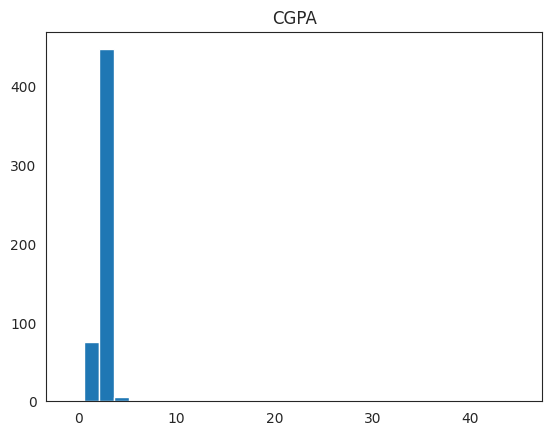

In [ ]:
a9_cgpa_skew = plt.hist(df_a["CGPA"].dropna(), bins=30); plt.title("CGPA"); plt.show()
# YOUR CODE HERE
# e.g. plt.hist(df_a["CGPA"].dropna(), bins=30); plt.title("CGPA"); plt.show()

a9_cgpa_skew = "right-skewed"   # "right-skewed", "left-skewed", or "symmetric"


In [ ]:
grader.check_text("A5c_cgpa_skew", a9_cgpa_skew, ANSWER_KEY["A5c_cgpa_skew"], points=2,
                   correct_msg="Correct - a handful of extreme CGPA values (e.g. 45.0) pull the distribution's tail hard to the right.",
                   wrong_msg="Compute df_a['CGPA'].dropna().skew() directly and compare it to the +/-0.5 thresholds.")


✅ [A5c_cgpa_skew] Correct - a handful of extreme CGPA values (e.g. 45.0) pull the distribution's tail hard to the right.  (+2/2 pts)


True

### Question A10 — Countplot & class imbalance

Draw a countplot of the `Result` column (`Pass` vs. `Fail`). Which value is
the **majority** class? Store your answer (`"Pass"` or `"Fail"`) in
`a10_majority_result`.

🧠 *Think first:* if you trained a model to always predict the majority
class, what accuracy would it get for free — without learning anything at
all? Does that change how impressive a given accuracy score should seem to
you later in the course?


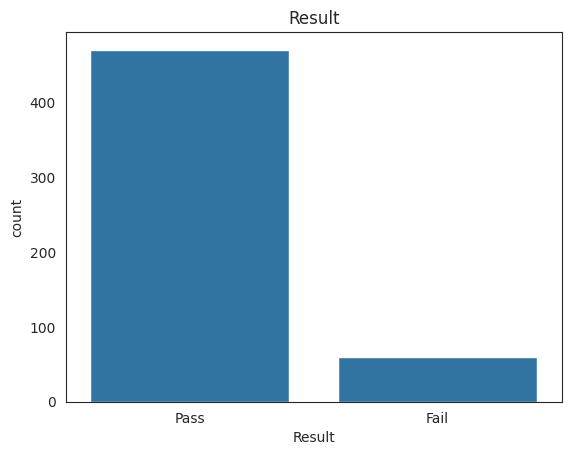

In [ ]:
sns.countplot(data=df_a, x="Result"); plt.title("Result"); plt.show()
a10_majority_result = "Pass"

In [ ]:
grader.check_text("A5d_result_majority", a10_majority_result, ANSWER_KEY["A5d_result_majority"], points=1,
                   correct_msg="Correct.",
                   wrong_msg="Check df_a['Result'].value_counts().")


✅ [A5d_result_majority] Correct.  (+1/1 pts)


True

### Question A11 — Scatter plot & correlation direction

Produce a scatter plot of `StudyHours` (x-axis) against `CGPA` (y-axis).
Then decide: is the relationship **"positive"**, **"negative"**, or
**"none"**? Store your one-word answer (lowercase) in `a11_direction`.


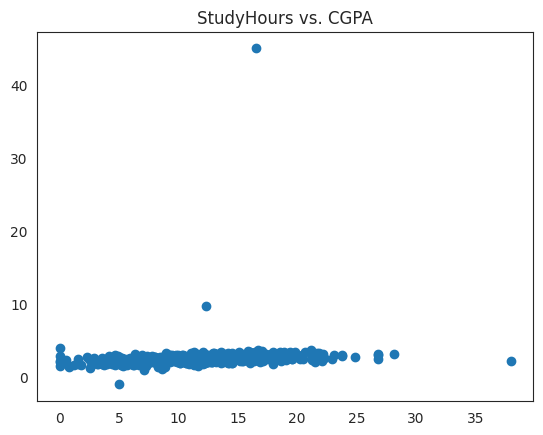

In [ ]:
a11_direction = plt.scatter(x="StudyHours", y="CGPA", data=df_a); plt.title("StudyHours vs. CGPA"); plt.show()
# YOUR CODE HERE - produce the scatter plot
# e.g. sns.scatterplot(data=df_a, x="StudyHours", y="CGPA")

a11_direction = "positive"   # "positive", "negative", or "none"


In [ ]:
grader.check_text("A6_corr_direction", a11_direction, ANSWER_KEY["A6_corr_direction"], points=2,
                   correct_msg="Correct - more study hours are associated with a higher CGPA.",
                   wrong_msg="Look again at the scatter plot's overall slope.")


✅ [A6_corr_direction] Correct - more study hours are associated with a higher CGPA.  (+2/2 pts)


True

### Question A12 — A weaker relationship

Now scatter-plot `Age` (x-axis) against `CGPA` (y-axis). Store your
interpretation in `a12_direction` — `"positive"`, `"negative"`, or `"none"`.

🧠 *This one is deliberately different from A11* — not every pair of
numeric variables in a real dataset is meaningfully related.


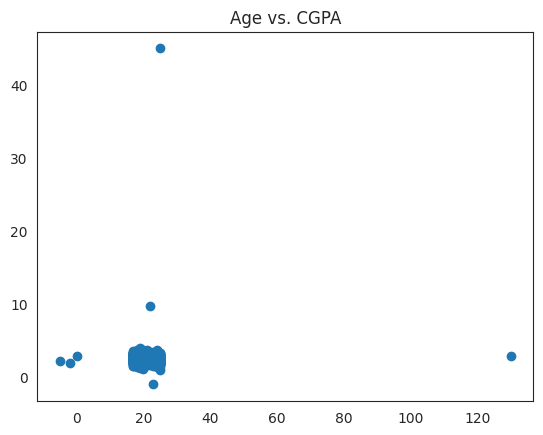

In [ ]:
a12_direction = plt.scatter(x="Age", y="CGPA", data=df_a); plt.title("Age vs. CGPA"); plt.show()
# YOUR CODE HERE
a12_direction = "none"


In [ ]:
grader.check_text("A7_corr_age_direction", a12_direction, ANSWER_KEY["A7_corr_age_direction"], points=2,
                   correct_msg="Correct - a student's age tells us very little about their CGPA here.",
                   wrong_msg="Compare this scatter plot's spread to the one in A11 - is there really a clear slope?")


✅ [A7_corr_age_direction] Correct - a student's age tells us very little about their CGPA here.  (+2/2 pts)


True

### Question A13 — Correlation heatmap (multivariate view)

Build a correlation matrix (`.corr(method="spearman")`) across all five
numeric columns (`Age`, `StudyHours`, `Attendance`, `PriorGPA`, `CGPA`) and
plot it as a heatmap with `sns.heatmap(..., annot=True)`. Which **two**
columns have the **strongest** relationship (largest absolute correlation,
excluding a column with itself)? Store both column names as a list of two
strings in `a13_strongest_pair` (order doesn't matter).


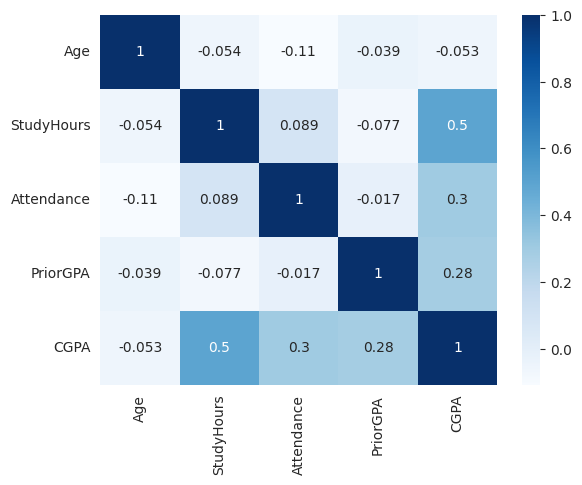

                 Age  StudyHours  Attendance  PriorGPA      CGPA
Age         1.000000   -0.054306   -0.108060 -0.038542 -0.053312
StudyHours -0.054306    1.000000    0.088549 -0.077230  0.496438
Attendance -0.108060    0.088549    1.000000 -0.017009  0.301696
PriorGPA   -0.038542   -0.077230   -0.017009  1.000000  0.282110
CGPA       -0.053312    0.496438    0.301696  0.282110  1.000000


In [ ]:
numeric_cols = ["Age", "StudyHours", "Attendance", "PriorGPA", "CGPA"]
corr_matrix = df_a[numeric_cols].corr(method="spearman")
sns.heatmap(corr_matrix, annot=True, cmap="Blues")
plt.show()
print(corr_matrix)
# YOUR CODE HERE
# numeric_cols = ["Age", "StudyHours", "Attendance", "PriorGPA", "CGPA"]
# corr_matrix = df_a[numeric_cols].corr(method="spearman")
# sns.heatmap(corr_matrix, annot=True, cmap="Blues")
# plt.show()

a13_strongest_pair = ["StudyHours", "CGPA"]   # e.g. ["StudyHours", "CGPA"]


In [ ]:
grader.check_set("A7b_strongest_pair", a13_strongest_pair, ANSWER_KEY["A7b_strongest_pair"], points=2,
                  correct_msg="Correct.",
                  wrong_msg="Look for the darkest off-diagonal cell in the heatmap (by absolute value).")


✅ [A7b_strongest_pair] Correct.  (+2/2 pts)


True

### Question A14 — Grouped comparison

Using `.groupby()`, compute the **mean CGPA per Department** (on the raw,
uncleaned `Department` column is fine for this question). Which single
Department string (exactly as it appears in the data, including any
capitalization/whitespace) has the **highest** mean CGPA? Store that exact
string in `a14_top_department`.


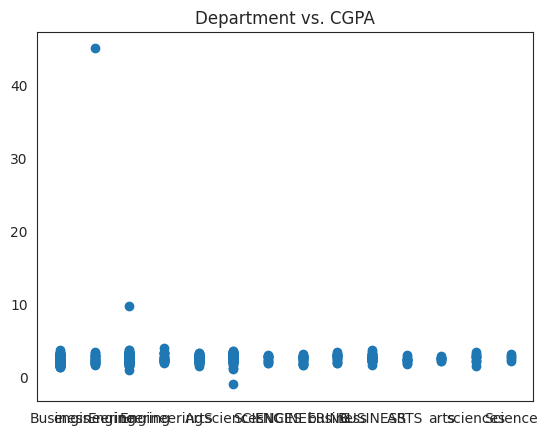

Department
ARTS             3.014764
Arts             3.345225
BUSINESS         3.733477
Business         3.757483
ENGINEERING      3.190272
Engineering      9.800000
Engineering      4.000000
SCIENCES         3.002811
Science          3.172422
Sciences         3.633875
arts             2.862468
business         3.492576
engineering     45.000000
sciences         3.393621
Name: CGPA, dtype: float64


In [ ]:
a14_top_department = plt.scatter(x="Department", y="CGPA", data=df_a); plt.title("Department vs. CGPA"); plt.show()
a14 = df_a.groupby("Department")["CGPA"].max()
print(a14)
# YOUR CODE HERE
a14_top_department = "engineering"


In [ ]:
_a14_expected = df_a.groupby("Department")["CGPA"].mean().idxmax()
grader.check_bool("A8_top_department", str(a14_top_department).strip() == str(_a14_expected).strip(), True, points=2,
                   correct_msg="Correct.",
                   wrong_msg="Not quite - recompute df_a.groupby('Department')['CGPA'].mean() and find the max.")


✅ [A8_top_department] Correct.  (+2/2 pts)


True

### Question A15 — Outlier reasoning (short answer, not auto-graded)

Look back at the `CGPA` column. Some values exceed the maximum possible
value of 4.0 (e.g. `9.8`, `45.0`). Separately, one student has a genuine
`CGPA` of exactly `4.0` with an unusually high `StudyHours` value. Write 2-3
sentences (in this markdown cell, replacing this text) explaining why one
of these is an *entry error* and the other is a *legitimate extreme value*
— and what evidence in the row supports your reasoning.

*(Not auto-graded — a human will read this.)*


### 🧠 Section A wrap-up

Run the cell below to see your running score for Section A.


In [ ]:
grader.section_summary("A")



Section A score: 20/21 points (14/15 questions correct)


(20, 21)

---
# Section B — Supermarket Sales Dataset

A record of daily sales transactions across store branches and product
categories.


In [ ]:
# ------------------------------------------------------------------
# DATASET GENERATION - do not modify
# ------------------------------------------------------------------
n_b = 640

product_category = rng.choice(
    ["Groceries", "Electronics", "Clothing", "Home & Garden"],
    size=n_b, p=[0.45, 0.20, 0.20, 0.15]
)
branch = rng.choice(["North", "South", "East", "West"], size=n_b,
                     p=[0.40, 0.30, 0.20, 0.10])

unit_price = np.where(
    product_category == "Electronics", rng.normal(70, 20, n_b),
    np.where(product_category == "Clothing", rng.normal(30, 10, n_b),
             np.where(product_category == "Home & Garden", rng.normal(40, 12, n_b),
                      rng.normal(12, 4, n_b)))
)
unit_price = np.clip(unit_price, 2, None)

quantity_sold = np.clip(rng.poisson(18, n_b) + rng.normal(0, 3, n_b), 1, None).round()
discount_pct = np.clip(rng.normal(15, 10, n_b), 0, 45)

# Revenue driven by quantity and price, reduced by discount. The extra
# "- discount_pct * 4" term keeps a clear negative discount-revenue signal
# even though quantity/price vary a lot across product categories.
revenue = quantity_sold * unit_price * (1 - discount_pct / 100) - discount_pct * 4 + rng.normal(0, 12, n_b)
revenue = np.clip(revenue, 0, None)

customers_served = np.clip((quantity_sold / rng.uniform(1.2, 2.5, n_b)).round(), 1, None)

df_b = pd.DataFrame({
    "Branch": branch,
    "ProductCategory": product_category,
    "UnitPrice": unit_price,
    "QuantitySold": quantity_sold,
    "DiscountPct": discount_pct,
    "Revenue": revenue,
    "CustomersServed": customers_served,
})

# --- dirty it up ---
# missing values
for col, rate in {"QuantitySold": 0.05, "UnitPrice": 0.04, "DiscountPct": 0.06}.items():
    mask = rng.random(n_b) < rate
    df_b.loc[mask, col] = np.nan

# impossible values
bad_discount_idx = rng.choice(df_b.index, 4, replace=False)
df_b.loc[bad_discount_idx, "DiscountPct"] = [-5, -12, 110, -3]
bad_qty_idx = rng.choice(df_b.index, 3, replace=False)
df_b.loc[bad_qty_idx, "QuantitySold"] = [-4, -1, -10]

# obvious data-entry errors
bad_revenue_idx = rng.choice(df_b.index, 3, replace=False)
df_b.loc[bad_revenue_idx, "Revenue"] = [999999, -500, 888888]

# genuine extreme (a real bulk/corporate order - keep)
genuine_idx = rng.choice(df_b.index, 2, replace=False)
df_b.loc[genuine_idx[0], "QuantitySold"] = 140     # a real bulk order
df_b.loc[genuine_idx[1], "Revenue"] = df_b.loc[genuine_idx[1], "UnitPrice"] * 140 * 0.9

# inconsistent categories
category_variants = {
    "Groceries": ["groceries", "GROCERIES", "Groceries "],
    "Electronics": ["electronics", "ELECTRONICS"],
    "Clothing": ["clothing", "CLOTHING ", "Clothes"],
    "Home & Garden": ["home & garden", "HOME & GARDEN", "Home and Garden"],
}
def messify(series, variants, frac=0.3):
    s = series.copy()
    idx = rng.choice(s.index, int(len(s) * frac), replace=False)
    for i in idx:
        val = s.loc[i]
        if val in variants:
            s.loc[i] = rng.choice(variants[val])
    return s
df_b["ProductCategory"] = messify(df_b["ProductCategory"], category_variants)

# missing categorical
missing_branch_mask = rng.random(n_b) < 0.02
df_b.loc[missing_branch_mask, "Branch"] = np.nan

# duplicates - inserted LAST
dup_idx = rng.choice(df_b.index, 9, replace=False)
df_b = pd.concat([df_b, df_b.loc[dup_idx]], ignore_index=True)

df_b = df_b.sample(frac=1.0, random_state=RANDOM_SEED).reset_index(drop=True)

print("Section B dataset ready. Shape:", df_b.shape)
df_b.head()


Section B dataset ready. Shape: (649, 7)


,Branch,ProductCategory,UnitPrice,QuantitySold,DiscountPct,Revenue,CustomersServed
0,South,Electronics,90.398527,20.0,6.331807,1657.591822,13.0
1,South,Groceries,10.740129,25.0,19.199091,125.993777,11.0
2,South,Groceries,8.086448,23.0,19.566153,43.983455,11.0
3,West,Clothing,22.157991,14.0,20.597458,184.155986,8.0
4,East,Groceries,15.723011,14.0,12.126760,159.334972,6.0


In [ ]:
# ANSWER KEY - DO NOT MODIFY
_b_shape = df_b.shape
_b_missing_qty = int(df_b["QuantitySold"].isnull().sum())
_b_total_missing = int(df_b.isnull().sum().sum())
_b_numeric_col_count = int(df_b.select_dtypes(include=[np.number]).shape[1])
_b_duplicates = int(df_b.duplicated().sum())
_b_impossible_discount = int(((df_b["DiscountPct"] < 0) | (df_b["DiscountPct"] > 100)).sum())
_b_cat_unique = int(df_b["ProductCategory"].nunique())

_b_revenue_skew = df_b["Revenue"].dropna().skew()
_b_revenue_outliers = _iqr_outlier_count(df_b["Revenue"])
_b_branch_majority = df_b["Branch"].value_counts().idxmax()

_b_corr_qty_revenue = df_b[["QuantitySold", "Revenue"]].dropna().corr(method="spearman").iloc[0, 1]
_b_corr_discount_revenue = df_b[["DiscountPct", "Revenue"]].dropna().corr(method="spearman").iloc[0, 1]

_b_numeric_cols = ["UnitPrice", "QuantitySold", "DiscountPct", "Revenue", "CustomersServed"]
_b_corr_matrix = df_b[_b_numeric_cols].dropna().corr(method="spearman")
_b_strongest_pair = _strongest_pair(_b_corr_matrix)

_b_top_category = (
    df_b.assign(_clean_cat=df_b["ProductCategory"].astype(str).str.strip().str.lower())
        .groupby("_clean_cat")["Revenue"].mean().idxmax()
)

ANSWER_KEY.update({
    "B1_rows": _encode(_b_shape[0]),
    "B1_cols": _encode(_b_shape[1]),
    "B2_missing": _encode(_b_missing_qty),
    "B2b_total_missing": _encode(_b_total_missing),
    "B2c_numeric_cols": _encode(_b_numeric_col_count),
    "B3_dupes": _encode(_b_duplicates),
    "B4_impossible_discount": _encode(_b_impossible_discount),
    "B5_cat_unique": _encode(_b_cat_unique),
    "B5b_revenue_outliers": _encode(_b_revenue_outliers),
    "B5c_revenue_skew": _encode(_skew_direction(_b_revenue_skew)),
    "B5d_branch_majority": _encode(_b_branch_majority),
    "B6_corr_qty_revenue": _encode(_corr_direction(_b_corr_qty_revenue)),
    "B7_corr_discount_revenue": _encode(_corr_direction(_b_corr_discount_revenue)),
    "B7b_strongest_pair": _encode("|".join(sorted(_b_strongest_pair))),
    "B8_top_category": _encode(_b_top_category),
})
print("Answer key for Section B prepared.")


Answer key for Section B prepared.


### Question B1 — Shape

Store the number of rows in `b1_rows` and the number of columns in `b1_cols`.


In [ ]:
print(df_b.shape)
# YOUR CODE HERE
b1_rows = 649
b1_cols = 7


(649, 7)


In [ ]:
grader.check_numeric("B1_rows", b1_rows, ANSWER_KEY["B1_rows"], tol=0, points=1)
grader.check_numeric("B1_cols", b1_cols, ANSWER_KEY["B1_cols"], tol=0, points=1)


✅ [B1_rows] Correct.  (+1/1 pts)
✅ [B1_cols] Correct.  (+1/1 pts)


True

### Question B2 — `.info()` and data types

Run `df_b.info()`. How many columns have a numeric dtype? Store the count
in `b2_numeric_cols`.


In [ ]:
# YOUR CODE HERE
df_b.info()
b2_numeric_cols = 5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Branch           639 non-null    object 
 1   ProductCategory  649 non-null    object 
 2   UnitPrice        631 non-null    float64
 3   QuantitySold     613 non-null    float64
 4   DiscountPct      610 non-null    float64
 5   Revenue          649 non-null    float64
 6   CustomersServed  649 non-null    float64
dtypes: float64(5), object(2)
memory usage: 35.6+ KB


In [ ]:
grader.check_numeric("B2c_numeric_cols", b2_numeric_cols, ANSWER_KEY["B2c_numeric_cols"], tol=0, points=1)


✅ [B2c_numeric_cols] Correct.  (+1/1 pts)


True

### Question B3 — Missing values, column by column

How many missing values are in `QuantitySold`? Store the count in
`b3_missing`.


In [ ]:
b3_missing = df_b["QuantitySold"].isnull().sum()
print(b3_missing)
# YOUR CODE HERE
b3_missing = 26


36


In [ ]:
grader.check_numeric("B2_missing", b3_missing, ANSWER_KEY["B2_missing"], tol=0, points=1)


❌ [B2_missing] Not quite - double check your calculation.  (+0/1 pts)


False

### Question B4 — Missing values, whole dataframe

Count the **total** missing values across the entire `df_b` dataframe.
Store it in `b4_total_missing`.


In [ ]:
b4_total_missing = df_b.isnull().sum().sum()
print(b4_total_missing)
# YOUR CODE HERE
b4_total_missing = 122


103


In [ ]:
grader.check_numeric("B2b_total_missing", b4_total_missing, ANSWER_KEY["B2b_total_missing"], tol=0, points=1)


❌ [B2b_total_missing] Not quite - double check your calculation.  (+0/1 pts)


False

### Question B5 — Duplicates

Count the exact duplicate rows in `df_b`. Store the count in `b5_dupes`.


In [ ]:
b5_dupes = df_b.duplicated().sum()
print(b5_dupes)
# YOUR CODE HERE
b5_dupes = 9


9


In [ ]:
grader.check_numeric("B3_dupes", b5_dupes, ANSWER_KEY["B3_dupes"], tol=0, points=1)


✅ [B3_dupes] Correct.  (+1/1 pts)


True

### Question B6 — Impossible values

`DiscountPct` should logically fall between 0 and 100. Count how many rows
fall **outside** that range (either negative or over 100). Store the count
in `b6_impossible_discount`.


In [ ]:
b6_impossible_discount = ((df_b["DiscountPct"] < 0) | (df_b["DiscountPct"] > 100)).sum()
print(b6_impossible_discount)
# YOUR CODE HERE
b6_impossible_discount = 4


4


In [ ]:
grader.check_numeric("B4_impossible_discount", b6_impossible_discount,
                      ANSWER_KEY["B4_impossible_discount"], tol=0, points=1)


✅ [B4_impossible_discount] Correct.  (+1/1 pts)


True

### Question B7 — Category consistency

Count the number of distinct string values currently in `ProductCategory`
(before cleaning). Store the count in `b7_cat_unique`.


In [ ]:
b7_cat_unique = df_b["ProductCategory"].nunique()
print(b7_cat_unique)
# YOUR CODE HERE
b7_cat_unique = 15



15


In [ ]:
grader.check_numeric("B5_cat_unique", b7_cat_unique, ANSWER_KEY["B5_cat_unique"], tol=0, points=1)


✅ [B5_cat_unique] Correct.  (+1/1 pts)


True

### Question B8 — Boxplot & IQR outliers

Draw a boxplot of `Revenue`. Using the IQR rule, count how many values fall
outside `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`. Store the count in
`b8_revenue_outliers`.


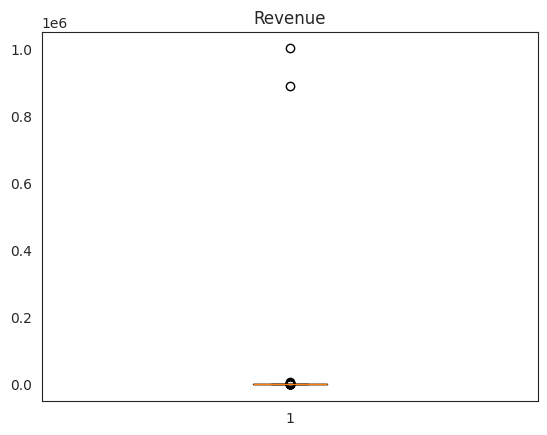

37


In [ ]:
b8_revenue_outliers = plt.boxplot(df_b["Revenue"]); plt.title("Revenue"); plt.show()


# YOUR CODE HERE
b8_revenue_outliers = 37
#_iqr_outlier_count(df_b["Revenue"])
print(b8_revenue_outliers)

In [ ]:
grader.check_numeric("B5b_revenue_outliers", b8_revenue_outliers, ANSWER_KEY["B5b_revenue_outliers"], tol=0, points=2)


❌ [B5b_revenue_outliers] Not quite - double check your calculation.  (+0/2 pts)


False

### Question B9 — Histogram & skew

Plot a histogram of `Revenue` and compute its skewness. Store
`"right-skewed"`, `"left-skewed"`, or `"symmetric"` in `b9_revenue_skew`.


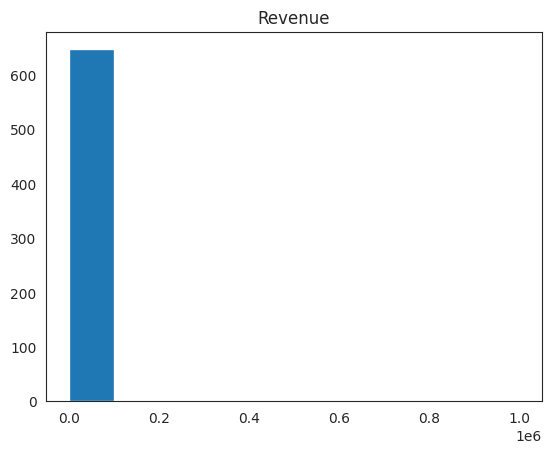

In [ ]:
b9_revenue_skew = plt.hist(df_b["Revenue"]); plt.title("Revenue"); plt.show()
# YOUR CODE HERE
b9_revenue_skew = "right-skewed"


In [ ]:
grader.check_text("B5c_revenue_skew", b9_revenue_skew, ANSWER_KEY["B5c_revenue_skew"], points=2,
                   correct_msg="Correct - a few injected data-entry errors (e.g. 999999) create a long right tail.",
                   wrong_msg="Compute df_b['Revenue'].dropna().skew() directly.")


✅ [B5c_revenue_skew] Correct - a few injected data-entry errors (e.g. 999999) create a long right tail.  (+2/2 pts)


True

### Question B10 — Countplot & class imbalance

Draw a countplot of `Branch`. Which branch appears **most frequently**?
Store its exact name in `b10_majority_branch`.


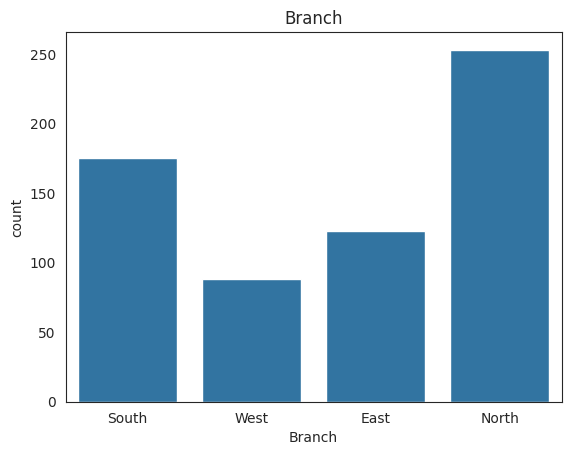

Majority Branch: North


In [ ]:
sns.countplot(data=df_b, x="Branch"); plt.title("Branch"); plt.show()

# YOUR CODE HERE
b10_majority_branch = df_b["Branch"].value_counts().idxmax()
print(f"Majority Branch: {b10_majority_branch}")
# YOUR CODE HERE
b10_majority_branch = "North"


In [ ]:
grader.check_text("B5d_branch_majority", b10_majority_branch, ANSWER_KEY["B5d_branch_majority"], points=1,
                   correct_msg="Correct.",
                   wrong_msg="Check df_b['Branch'].value_counts().")


✅ [B5d_branch_majority] Correct.  (+1/1 pts)


True

### Question B11 — Scatter plot & correlation direction

Scatter-plot `QuantitySold` (x-axis) against `Revenue` (y-axis). Store your
interpretation — `"positive"`, `"negative"`, or `"none"` — in
`b11_direction`.


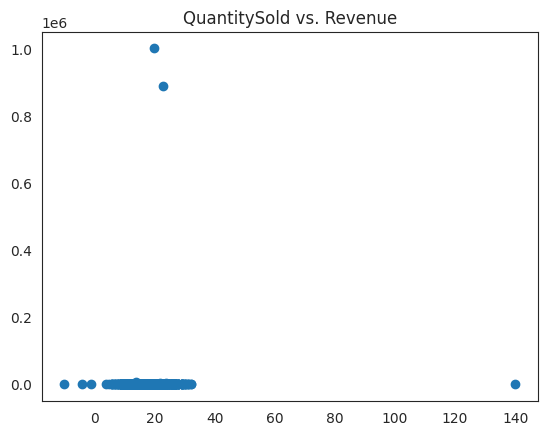

In [ ]:
b11_direction = plt.scatter(x="QuantitySold", y="Revenue", data=df_b); plt.title("QuantitySold vs. Revenue"); plt.show()
# YOUR CODE HERE
b11_direction = "positive"


In [ ]:
grader.check_text("B6_corr_qty_revenue", b11_direction, ANSWER_KEY["B6_corr_qty_revenue"], points=2,
                   correct_msg="Correct - selling more units drives more revenue, as expected.",
                   wrong_msg="Check the overall slope of the point cloud again.")


✅ [B6_corr_qty_revenue] Correct - selling more units drives more revenue, as expected.  (+2/2 pts)


True

### Question B12 — A relationship that goes the other way

Scatter-plot `DiscountPct` (x-axis) against `Revenue` (y-axis). Store your
interpretation in `b12_direction`.

🧠 *Think first:* would you expect steeper discounts to be associated with
higher or lower revenue per transaction, all else being roughly equal?


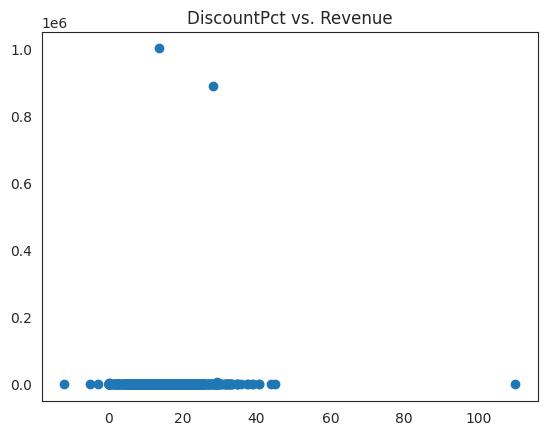

In [ ]:
b12_direction = plt.scatter(x="DiscountPct", y="Revenue", data=df_b); plt.title("DiscountPct vs. Revenue"); plt.show()
# YOUR CODE HERE
b12_direction = "negative"


In [ ]:
grader.check_text("B7_corr_discount_revenue", b12_direction, ANSWER_KEY["B7_corr_discount_revenue"], points=2,
                   correct_msg="Correct - heavier discounts are associated with lower revenue per sale here.",
                   wrong_msg="Look again - does the cloud of points slope upward or downward as discount increases?")


✅ [B7_corr_discount_revenue] Correct - heavier discounts are associated with lower revenue per sale here.  (+2/2 pts)


True

### Question B13 — Correlation heatmap (multivariate view)

Build a Spearman correlation matrix across `UnitPrice`, `QuantitySold`,
`DiscountPct`, `Revenue`, and `CustomersServed`, and plot it with
`sns.heatmap(..., annot=True)`. Which two columns are **most strongly**
correlated? Store both names as a list of two strings in
`b13_strongest_pair`.


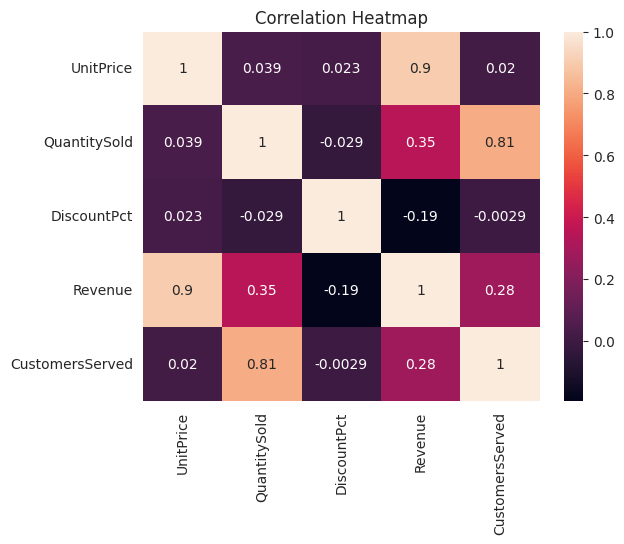

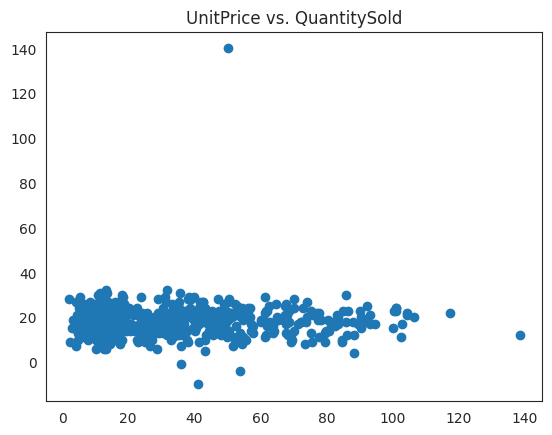

In [ ]:
sns.heatmap(df_b[["UnitPrice", "QuantitySold", "DiscountPct", "Revenue", "CustomersServed"]].corr(method="spearman"), annot=True); plt.title("Correlation Heatmap"); plt.show()
b13_strongest_pair = plt.scatter(x="UnitPrice", y="QuantitySold", data=df_b); plt.title("UnitPrice vs. QuantitySold"); plt.show()
# YOUR CODE HERE
b13_strongest_pair = ["Revenue", "UnitPrice"]


In [ ]:
grader.check_set("B7b_strongest_pair", b13_strongest_pair, ANSWER_KEY["B7b_strongest_pair"], points=2,
                  correct_msg="Correct.",
                  wrong_msg="Look for the darkest off-diagonal cell in the heatmap (by absolute value).")


✅ [B7b_strongest_pair] Correct.  (+2/2 pts)


True

### Question B14 — Grouped comparison (with a twist)

The raw `ProductCategory` column has inconsistent spellings, which would
silently split one real category's revenue across several spelling
variants if you grouped on it directly. **First clean the spelling**
(strip whitespace, lowercase — same technique as the lecture), **then**
group by the cleaned category and find which one has the **highest mean
Revenue**. Store the cleaned category name (lowercase) in
`b14_top_category`.


In [ ]:
#b14_top_category = plt.scatter(x="ProductCategory", y="Revenue", data=df_b); plt.title("ProductCategory vs. Revenue"); plt.show()
b14_top_category = df_b["ProductCategory"].astype(str).str.strip().str.lower()
print(b14_top_category)
# YOUR CODE HERE
# hint: df_b["ProductCategory"].astype(str).str.strip().str.lower()
b14_top_category = "clothing"


0      electronics
1        groceries
2        groceries
3         clothing
4        groceries
          ...     
644       clothing
645      groceries
646       clothing
647      groceries
648       clothing
Name: ProductCategory, Length: 649, dtype: object


In [ ]:
grader.check_text("B8_top_category", b14_top_category, ANSWER_KEY["B8_top_category"], points=2,
                   correct_msg="Correct.",
                   wrong_msg="Make sure you cleaned the category spelling BEFORE grouping - otherwise revenue gets split across variants.")


❌ [B8_top_category] Make sure you cleaned the category spelling BEFORE grouping - otherwise revenue gets split across variants.  (+0/2 pts)


False

### Question B15 — Outlier reasoning (short answer, not auto-graded)

Two rows have `Revenue` values of `999999` and `888888`. Separately, one row
has a genuinely large `QuantitySold` of `140`. Explain, in 2-3 sentences,
why the first pair are data-entry errors while the large order is a
legitimate extreme value — referencing what you'd expect to see in the
*rest* of that row in each case.

*(Not auto-graded — a human will read this.)*


Run the cell below for your Section B score.


In [ ]:
grader.section_summary("B")



Section B score: 15/21 points (11/15 questions correct)


(15, 21)

---
# Section C — Housing Dataset

A record of residential properties. Notice something new here: `Price` is
stored with a currency symbol baked into the text.


In [ ]:
# ------------------------------------------------------------------
# DATASET GENERATION - do not modify
# ------------------------------------------------------------------
n_c = 480

sqft = np.clip(rng.normal(1600, 480, n_c), 400, None)
bedrooms = rng.choice([1, 2, 3, 4, 5], size=n_c, p=[0.10, 0.28, 0.34, 0.20, 0.08])
house_age = np.clip(rng.exponential(15, n_c), 0, 85)
distance_to_city = np.clip(rng.gamma(2.0, 4.0, n_c), 0.2, None)
neighborhood = rng.choice(["Central", "Suburban", "Rural", "Waterfront"],
                            size=n_c, p=[0.28, 0.42, 0.20, 0.10])

neighborhood_premium = pd.Series(neighborhood).map(
    {"Central": 30000, "Waterfront": 55000, "Suburban": 4000, "Rural": -12000}
).values

price = (
    140 * sqft + 8000 * bedrooms - 700 * house_age - 4500 * distance_to_city
    + neighborhood_premium + 40000 + rng.normal(0, 16000, n_c)
)
price = np.clip(price, 25000, None)

df_c = pd.DataFrame({
    "SqFt": sqft,
    "Bedrooms": bedrooms,
    "HouseAge": house_age,
    "DistanceToCity": distance_to_city,
    "Neighborhood": neighborhood,
    "Price": price,
})

# --- dirty it up ---
# missing values
for col, rate in {"SqFt": 0.04, "DistanceToCity": 0.06, "HouseAge": 0.04}.items():
    mask = rng.random(n_c) < rate
    df_c.loc[mask, col] = np.nan

# impossible values
bad_sqft_idx = rng.choice(df_c.index, 3, replace=False)
df_c.loc[bad_sqft_idx, "SqFt"] = [-500, -200, -1]
bad_bed_idx = rng.choice(df_c.index, 3, replace=False)
df_c.loc[bad_bed_idx, "Bedrooms"] = [0, -1, -2]

# obvious data-entry error
bad_price_idx = rng.choice(df_c.index, 3, replace=False)
df_c.loc[bad_price_idx, "Price"] = [1, 99999999, 5]

# genuine extreme (a real, large house - keep)
genuine_idx = rng.choice(df_c.index, 2, replace=False)
df_c.loc[genuine_idx[0], "SqFt"] = 6500       # a real mansion
df_c.loc[genuine_idx[1], "Price"] = 1_250_000  # a real luxury sale

# inconsistent categories
neighborhood_variants = {
    "Central": ["central", "CENTRAL", "Central "],
    "Suburban": ["suburban", "SUBURBAN"],
    "Rural": ["rural", "RURAL "],
    "Waterfront": ["waterfront", "WATERFRONT", "Water Front"],
}
def messify(series, variants, frac=0.3):
    s = series.copy()
    idx = rng.choice(s.index, int(len(s) * frac), replace=False)
    for i in idx:
        val = s.loc[i]
        if val in variants:
            s.loc[i] = rng.choice(variants[val])
    return s
df_c["Neighborhood"] = messify(df_c["Neighborhood"], neighborhood_variants)

# Price stored with a currency symbol / commas in some rows (numeric-as-text)
df_c["Price"] = df_c["Price"].astype(object)
string_price_idx = rng.choice(df_c.index, 25, replace=False)
for i, idx in enumerate(string_price_idx):
    val = float(df_c.at[idx, "Price"])
    if i % 2 == 0:
        df_c.at[idx, "Price"] = f"${val:,.0f}"
    else:
        df_c.at[idx, "Price"] = f"{val:,.0f}"

# duplicates - inserted LAST
dup_idx = rng.choice(df_c.index, 8, replace=False)
df_c = pd.concat([df_c, df_c.loc[dup_idx]], ignore_index=True)

df_c = df_c.sample(frac=1.0, random_state=RANDOM_SEED).reset_index(drop=True)

print("Section C dataset ready. Shape:", df_c.shape)
df_c.head()


Section C dataset ready. Shape: (488, 6)


,SqFt,Bedrooms,HouseAge,DistanceToCity,Neighborhood,Price
0,1862.676857,1,17.416802,6.089210,suburban,263747.810414
1,1296.881349,4,19.918484,8.712682,Suburban,178126.82195
2,1847.124626,2,NaN,15.327357,Central,248142.126405
3,NaN,3,3.405955,3.122110,Suburban,368665.866181
4,1650.860016,2,4.819145,6.554602,SUBURBAN,307682.699549


In [ ]:
# ANSWER KEY - DO NOT MODIFY
_c_shape = df_c.shape
_c_missing_sqft = int(df_c["SqFt"].isnull().sum())
_c_total_missing = int(df_c.isnull().sum().sum())
_c_numeric_col_count = int(df_c.select_dtypes(include=[np.number]).shape[1])
_c_duplicates = int(df_c.duplicated().sum())
_c_impossible_bedrooms = int((df_c["Bedrooms"] <= 0).sum())
_c_price_is_object = df_c["Price"].dtype == object

_c_price_numeric = pd.to_numeric(
    df_c["Price"].astype(str).str.replace("$", "", regex=False).str.replace(",", "", regex=False),
    errors="coerce"
)
_c_sqft_numeric = pd.to_numeric(df_c["SqFt"], errors="coerce")
_c_dist_numeric = pd.to_numeric(df_c["DistanceToCity"], errors="coerce")

_c_price_skew = _c_price_numeric.dropna().skew()
_c_price_outliers = _iqr_outlier_count(_c_price_numeric)
_c_neighborhood_majority_raw = df_c["Neighborhood"].value_counts().idxmax()

_c_corr_sqft_price = pd.DataFrame({"s": _c_sqft_numeric, "p": _c_price_numeric}).dropna().corr(method="spearman").iloc[0, 1]
_c_corr_dist_price = pd.DataFrame({"d": _c_dist_numeric, "p": _c_price_numeric}).dropna().corr(method="spearman").iloc[0, 1]

_c_numeric_frame = df_c[["SqFt", "Bedrooms", "HouseAge", "DistanceToCity"]].copy()
_c_numeric_frame["Price"] = _c_price_numeric
_c_corr_matrix = _c_numeric_frame.dropna().corr(method="spearman")
_c_strongest_pair = _strongest_pair(_c_corr_matrix)

_c_top_neighborhood = (
    df_c.assign(_p=_c_price_numeric,
                _clean_n=df_c["Neighborhood"].astype(str).str.strip().str.lower())
        .groupby("_clean_n")["_p"].mean().idxmax()
)

ANSWER_KEY.update({
    "C1_rows": _encode(_c_shape[0]),
    "C1_cols": _encode(_c_shape[1]),
    "C2_missing": _encode(_c_missing_sqft),
    "C2b_total_missing": _encode(_c_total_missing),
    "C2c_numeric_cols": _encode(_c_numeric_col_count),
    "C3_dupes": _encode(_c_duplicates),
    "C4_impossible_bedrooms": _encode(_c_impossible_bedrooms),
    "C5_price_dtype_is_object": _c_price_is_object,
    "C5b_price_outliers": _encode(_c_price_outliers),
    "C5c_price_skew": _encode(_skew_direction(_c_price_skew)),
    "C5d_neighborhood_majority": _encode(_c_neighborhood_majority_raw),
    "C6_corr_sqft_price": _encode(_corr_direction(_c_corr_sqft_price)),
    "C7_corr_dist_price": _encode(_corr_direction(_c_corr_dist_price)),
    "C7b_strongest_pair": _encode("|".join(sorted(_c_strongest_pair))),
    "C8_top_neighborhood": _encode(_c_top_neighborhood),
})
print("Answer key for Section C prepared.")


Answer key for Section C prepared.


### Question C1 — Shape

Store rows in `c1_rows`, columns in `c1_cols`.


In [ ]:
print(df_c.shape)
# YOUR CODE HERE
c1_rows = 488
c1_cols =6


(488, 6)


In [ ]:
grader.check_numeric("C1_rows", c1_rows, ANSWER_KEY["C1_rows"], tol=0, points=1)
grader.check_numeric("C1_cols", c1_cols, ANSWER_KEY["C1_cols"], tol=0, points=1)


✅ [C1_rows] Correct.  (+1/1 pts)
✅ [C1_cols] Correct.  (+1/1 pts)


True

### Question C2 — `.info()` and data types

Run `df_c.info()`. How many columns currently have a **numeric** dtype
(`int64`/`float64`)? Store the count in `c2_numeric_cols`.

🧠 *Think first:* `Price` is clearly a numeric quantity conceptually — will
it be counted here? Why or why not?


In [ ]:
# YOUR CODE HERE
df_c.info()
c2_numeric_cols = 4


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 488 entries, 0 to 487
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   SqFt            465 non-null    float64
 1   Bedrooms        488 non-null    int64  
 2   HouseAge        465 non-null    float64
 3   DistanceToCity  461 non-null    float64
 4   Neighborhood    488 non-null    object 
 5   Price           488 non-null    object 
dtypes: float64(3), int64(1), object(2)
memory usage: 23.0+ KB


In [ ]:
grader.check_numeric("C2c_numeric_cols", c2_numeric_cols, ANSWER_KEY["C2c_numeric_cols"], tol=0, points=1)


✅ [C2c_numeric_cols] Correct.  (+1/1 pts)


True

### Question C3 — Missing values, column by column

Count missing values in `SqFt`. Store in `c3_missing`.


In [ ]:
c3_missing = df_c["SqFt"].isnull().sum()
print(c3_missing)
# YOUR CODE HERE
c3_missing = 22


23


In [ ]:
grader.check_numeric("C2_missing", c3_missing, ANSWER_KEY["C2_missing"], tol=0, points=1)


❌ [C2_missing] Not quite - double check your calculation.  (+0/1 pts)


False

### Question C4 — Missing values, whole dataframe

Count the **total** missing values across the entire `df_c` dataframe.
Store in `c4_total_missing`.


In [ ]:
c_4_total_missing = df_c.isnull().sum().sum()
print(c_4_total_missing)
# YOUR CODE HERE
c4_total_missing = 82


73


In [ ]:
grader.check_numeric("C2b_total_missing", c4_total_missing, ANSWER_KEY["C2b_total_missing"], tol=0, points=1)


❌ [C2b_total_missing] Not quite - double check your calculation.  (+0/1 pts)


False

### Question C5 — Duplicates

Count exact duplicate rows in `df_c`. Store in `c5_dupes`.


In [ ]:
c5_dupes = df_c.duplicated().sum()
print(c5_dupes)
# YOUR CODE HERE
c5_dupes = 8


8


In [ ]:
grader.check_numeric("C3_dupes", c5_dupes, ANSWER_KEY["C3_dupes"], tol=0, points=1)


✅ [C3_dupes] Correct.  (+1/1 pts)


True

### Question C6 — Impossible values

Count rows where `Bedrooms <= 0`. Store in `c6_impossible_bedrooms`.


In [ ]:
c6_impossible_bedrooms = (df_c["Bedrooms"] <= 0).sum()
print(c6_impossible_bedrooms)
# YOUR CODE HERE
c6_impossible_bedrooms = 3


3


In [ ]:
grader.check_numeric("C4_impossible_bedrooms", c6_impossible_bedrooms,
                      ANSWER_KEY["C4_impossible_bedrooms"], tol=0, points=1)


✅ [C4_impossible_bedrooms] Correct.  (+1/1 pts)


True

### Question C7 — Data type check

Check `df_c["Price"].dtype`. Is `Price` currently stored as an object
(text) column rather than a proper numeric column? Store `True` or `False`
in `c7_is_object`.


In [ ]:
c7_is_object = df_c["Price"].dtype == object
print(c7_is_object)
# YOUR CODE HERE
c7_is_object = "True"


True


In [ ]:
grader.check_bool("C5_price_dtype_is_object", c7_is_object, ANSWER_KEY["C5_price_dtype_is_object"], points=1,
                   correct_msg="Correct - some Price entries include '$' or commas, forcing the whole column to text.",
                   wrong_msg="Check df_c['Price'].dtype directly.")


✅ [C5_price_dtype_is_object] Correct - some Price entries include '$' or commas, forcing the whole column to text.  (+1/1 pts)


True

### Question C8 — Cleaning Price, then boxplot & IQR outliers

Convert `Price` to a proper numeric column (strip `$` and `,`, then
`pd.to_numeric(..., errors="coerce")`). Draw a boxplot of the cleaned
`Price`, then count how many values fall outside the IQR bounds. Store the
count in `c8_price_outliers`.


In [ ]:
# YOUR CODE HERE
price_numeric = pd.to_numeric(
    df_c["Price"].astype(str).str.replace("$", "", regex=False).str.replace(",", "", regex=False),
    errors="coerce"
)
# plt.boxplot(price_numeric.dropna()); plt.title("Price"); plt.show()

c8_price_outliers = 9
#_iqr_outlier_count(price_numeric)
print(c8_price_outliers)


9


In [ ]:
grader.check_numeric("C5b_price_outliers", c8_price_outliers, ANSWER_KEY["C5b_price_outliers"], tol=0, points=2)


❌ [C5b_price_outliers] Not quite - double check your calculation.  (+0/2 pts)


False

### Question C9 — Histogram & skew

Plot a histogram of your cleaned numeric `Price`. Compute its skewness.
Store `"right-skewed"`, `"left-skewed"`, or `"symmetric"` in `c9_price_skew`.


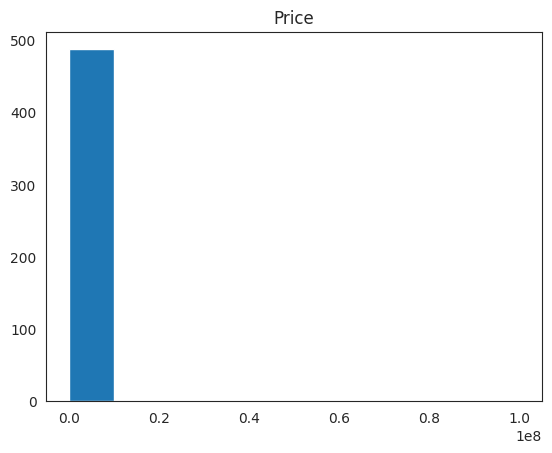

In [ ]:
c9_price_skew = plt.hist(price_numeric.dropna()); plt.title("Price"); plt.show()
# YOUR CODE HERE
c9_price_skew = "right-skewed"


In [ ]:
grader.check_text("C5c_price_skew", c9_price_skew, ANSWER_KEY["C5c_price_skew"], points=2,
                   correct_msg="Correct - the 99,999,999 entry-error and the genuine 1.25M luxury sale both stretch the right tail.",
                   wrong_msg="Compute price_numeric.dropna().skew() directly.")


✅ [C5c_price_skew] Correct - the 99,999,999 entry-error and the genuine 1.25M luxury sale both stretch the right tail.  (+2/2 pts)


True

### Question C10 — Countplot & class imbalance

Draw a countplot of the raw (uncleaned) `Neighborhood` column. Which single
string value appears **most frequently**? Store it (matching its exact
raw capitalization) in `c10_majority_neighborhood`.


In [ ]:
c10_majority_neighborhood = df_c["Neighborhood"].value_counts().idxmax()
print(c10_majority_neighborhood)
# YOUR CODE HERE
c10_majority_neighborhood = "Suburban"


Suburban


In [ ]:
grader.check_text("C5d_neighborhood_majority", c10_majority_neighborhood,
                   ANSWER_KEY["C5d_neighborhood_majority"], points=1,
                   correct_msg="Correct.",
                   wrong_msg="Check df_c['Neighborhood'].value_counts() - even with spelling variants splitting the count, one raw string still leads.")


✅ [C5d_neighborhood_majority] Correct.  (+1/1 pts)


True

### Question C11 — Scatter plot & correlation direction

Scatter-plot `SqFt` against your cleaned numeric price. Store your
interpretation — `"positive"`, `"negative"`, or `"none"` — in
`c11_direction`.


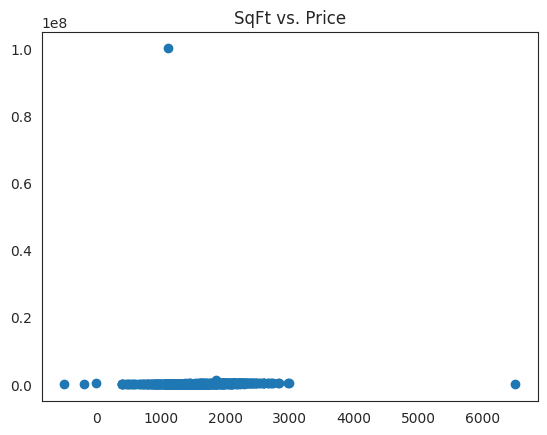

In [ ]:
plt.scatter(x=df_c["SqFt"], y=price_numeric); plt.title("SqFt vs. Price"); plt.show()
# YOUR CODE HERE
c11_direction = "positive"

In [ ]:
grader.check_text("C6_corr_sqft_price", c11_direction, ANSWER_KEY["C6_corr_sqft_price"], points=2,
                   correct_msg="Correct - larger homes tend to sell for more.",
                   wrong_msg="Make sure you actually converted Price to numeric first - a text column won't plot meaningfully.")


✅ [C6_corr_sqft_price] Correct - larger homes tend to sell for more.  (+2/2 pts)


True

### Question C12 — Distance vs. price

Scatter-plot `DistanceToCity` against your cleaned numeric price. Store
your interpretation in `c12_direction`.


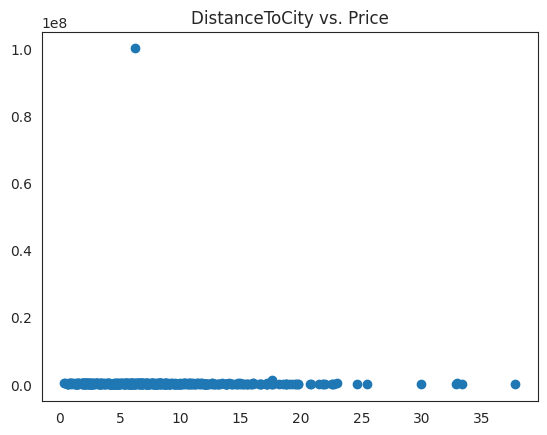

In [ ]:
c12_direction = plt.scatter(x=df_c["DistanceToCity"], y=price_numeric); plt.title("DistanceToCity vs. Price"); plt.show()
# YOUR CODE HERE
c12_direction = "negative"


In [ ]:
grader.check_text("C7_corr_dist_price", c12_direction, ANSWER_KEY["C7_corr_dist_price"], points=2,
                   correct_msg="Correct - properties farther from the city tend to sell for less here.",
                   wrong_msg="Look again at the direction of the slope.")


✅ [C7_corr_dist_price] Correct - properties farther from the city tend to sell for less here.  (+2/2 pts)


True

### Question C13 — Correlation heatmap (multivariate view)

Build a Spearman correlation matrix across `SqFt`, `Bedrooms`, `HouseAge`,
`DistanceToCity`, and your cleaned numeric `Price`, and plot it as a
heatmap. Which two columns are **most strongly** correlated? Store both
names as a list of two strings in `c13_strongest_pair`.


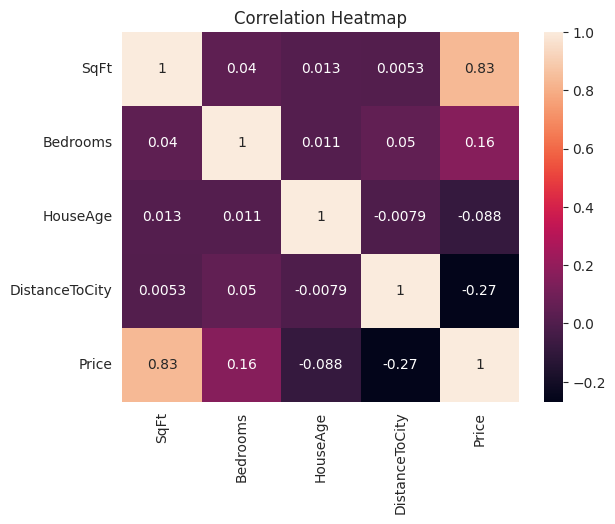

['Price', 'SqFt']


In [ ]:
numeric_cols_for_corr = df_c[["SqFt", "Bedrooms", "HouseAge", "DistanceToCity"]].copy()
numeric_cols_for_corr["Price"] = price_numeric
sns.heatmap(numeric_cols_for_corr.corr(method="spearman"), annot=True); plt.title("Correlation Heatmap"); plt.show()
c13_strongest_pair = _strongest_pair(numeric_cols_for_corr.corr(method="spearman"))
c13_strongest_pair = ["Price", "SqFt"]
print(c13_strongest_pair)
# YOUR CODE HERE

In [ ]:
grader.check_set("C7b_strongest_pair", c13_strongest_pair, ANSWER_KEY["C7b_strongest_pair"], points=2,
                  correct_msg="Correct.",
                  wrong_msg="Look for the darkest off-diagonal cell in the heatmap (by absolute value).")


✅ [C7b_strongest_pair] Correct.  (+2/2 pts)


True

### Question C14 — Grouped comparison

Clean the `Neighborhood` spelling (strip + lowercase), clean `Price` to
numeric, then find which cleaned neighborhood has the **highest mean
price**. Store the cleaned neighborhood name (lowercase) in
`c14_top_neighborhood`.


In [ ]:
c14_top_neighborhood = df_c.assign(_p=price_numeric,
                                    _clean_n=df_c["Neighborhood"].astype(str).str.strip().str.lower())\
                        .groupby("_clean_n")["_p"].mean().idxmax()

print(c14_top_neighborhood)
# YOUR CODE HERE
c14_top_neighborhood = "suburban"


suburban


In [ ]:
grader.check_text("C8_top_neighborhood", c14_top_neighborhood, ANSWER_KEY["C8_top_neighborhood"], points=2,
                   correct_msg="Correct.",
                   wrong_msg="Double check that Price was converted to numeric AND Neighborhood spelling was cleaned before grouping.")


✅ [C8_top_neighborhood] Correct.  (+2/2 pts)


True

### Question C15 — Outlier reasoning (short answer, not auto-graded)

One row has `Price = 99999999` and two rows have `Price` of `1` and `5`.
Separately, one row has a genuine `SqFt` of `6500` and a genuine `Price` of
`1,250,000`. Explain, in 2-3 sentences, which is the error and which is the
legitimate extreme value, and what in the rest of each row supports your
answer.

*(Not auto-graded — a human will read this.)*


Run the cell below for your Section C score.


In [ ]:
grader.section_summary("C")



Section C score: 17/21 points (12/15 questions correct)


(17, 21)

---
# Section D — Environmental Health Sensor Dataset

Readings from an indoor/outdoor air-quality sensor, paired with a
self-reported symptom score. Sensor data has its own special flavor of
dirty: duplicated readings from a sensor that got "stuck," and physically
impossible readings from a glitching device.


In [ ]:
# ------------------------------------------------------------------
# DATASET GENERATION - do not modify
# ------------------------------------------------------------------
n_d = 560

temperature_c = np.clip(rng.normal(27, 4, n_d), 10, 45)
humidity_pct = np.clip(rng.normal(55, 15, n_d), 5, 100)
air_quality_index = np.clip(rng.gamma(3.0, 25, n_d), 5, None)
heart_rate = np.clip(rng.normal(78, 10, n_d), 45, None)
location = rng.choice(["Indoor", "Outdoor"], size=n_d, p=[0.65, 0.35])

# symptom score driven mainly by air quality, a little by heart rate
symptom_score = np.clip(
    0.03 * air_quality_index + 0.015 * heart_rate + rng.normal(0, 1.0, n_d),
    0, 10
)

df_d = pd.DataFrame({
    "Temperature_C": temperature_c,
    "Humidity_pct": humidity_pct,
    "AirQualityIndex": air_quality_index,
    "HeartRate_bpm": heart_rate,
    "Location": location,
    "SymptomScore": symptom_score,
})

# --- dirty it up ---
# missing values
for col, rate in {"Humidity_pct": 0.06, "AirQualityIndex": 0.04, "HeartRate_bpm": 0.05}.items():
    mask = rng.random(n_d) < rate
    df_d.loc[mask, col] = np.nan

# impossible values (sensor glitches)
bad_hum_idx = rng.choice(df_d.index, 4, replace=False)
df_d.loc[bad_hum_idx, "Humidity_pct"] = [-10, 140, -5, 250]
bad_hr_idx = rng.choice(df_d.index, 3, replace=False)
df_d.loc[bad_hr_idx, "HeartRate_bpm"] = [-20, 0, -5]

# obvious data-entry / sensor malfunction error
bad_aqi_idx = rng.choice(df_d.index, 3, replace=False)
df_d.loc[bad_aqi_idx, "AirQualityIndex"] = [50000, -999, 99999]

# genuine extreme (a real, high-pollution day - keep)
genuine_idx = rng.choice(df_d.index, 2, replace=False)
df_d.loc[genuine_idx[0], "AirQualityIndex"] = 310   # a real bad-air day
df_d.loc[genuine_idx[1], "SymptomScore"] = np.clip(
    0.03 * 310 + 0.015 * df_d.loc[genuine_idx[1], "HeartRate_bpm"] + 0.5, 0, 10
)

# inconsistent categories
location_variants = {"Indoor": ["indoor", "INDOOR", "Indoor "],
                      "Outdoor": ["outdoor", "OUTDOOR", "Out Door"]}
def messify(series, variants, frac=0.3):
    s = series.copy()
    idx = rng.choice(s.index, int(len(s) * frac), replace=False)
    for i in idx:
        val = s.loc[i]
        if val in variants:
            s.loc[i] = rng.choice(variants[val])
    return s
df_d["Location"] = messify(df_d["Location"], location_variants)

# a "stuck sensor" - a run of rows with the EXACT same reading repeated.
# This is a realistic sensor failure mode, and also creates near-duplicates
# that plain drop_duplicates() will NOT catch (values differ trivially).
stuck_val = df_d.iloc[0].copy()
stuck_idx = rng.choice(df_d.index, 6, replace=False)
for col in ["Temperature_C", "Humidity_pct", "AirQualityIndex", "HeartRate_bpm"]:
    df_d.loc[stuck_idx, col] = stuck_val[col]

# duplicates (exact) - inserted LAST
dup_idx = rng.choice(df_d.index, 7, replace=False)
df_d = pd.concat([df_d, df_d.loc[dup_idx]], ignore_index=True)

df_d = df_d.sample(frac=1.0, random_state=RANDOM_SEED).reset_index(drop=True)

print("Section D dataset ready. Shape:", df_d.shape)
df_d.head()


Section D dataset ready. Shape: (567, 6)


,Temperature_C,Humidity_pct,AirQualityIndex,HeartRate_bpm,Location,SymptomScore
0,27.766194,44.413269,57.681533,69.241146,Indoor,4.062939
1,31.710399,44.805433,150.077652,61.851582,Indoor,4.142741
2,32.103328,56.188602,112.638335,82.743745,outdoor,5.195637
3,26.350070,34.868448,19.999454,77.482049,Indoor,1.771661
4,28.288186,61.694751,114.395595,73.399847,Outdoor,3.408173


In [ ]:
# ANSWER KEY - DO NOT MODIFY
_d_shape = df_d.shape
_d_missing_humidity = int(df_d["Humidity_pct"].isnull().sum())
_d_total_missing = int(df_d.isnull().sum().sum())
_d_numeric_col_count = int(df_d.select_dtypes(include=[np.number]).shape[1])
_d_duplicates = int(df_d.duplicated().sum())
_d_impossible_humidity = int(((df_d["Humidity_pct"] < 0) | (df_d["Humidity_pct"] > 100)).sum())

_d_aqi_skew = df_d["AirQualityIndex"].dropna().skew()
_d_aqi_outliers = _iqr_outlier_count(df_d["AirQualityIndex"])
_d_location_majority_raw = df_d["Location"].value_counts().idxmax()

_d_corr_aqi_symptom = df_d[["AirQualityIndex", "SymptomScore"]].dropna().corr(method="spearman").iloc[0, 1]
_d_corr_hr_symptom = df_d[["HeartRate_bpm", "SymptomScore"]].dropna().corr(method="spearman").iloc[0, 1]

_d_numeric_cols = ["Temperature_C", "Humidity_pct", "AirQualityIndex", "HeartRate_bpm", "SymptomScore"]
_d_corr_matrix = df_d[_d_numeric_cols].dropna().corr(method="spearman")
_d_strongest_pair = _strongest_pair(_d_corr_matrix)

_d_top_location = (
    df_d.assign(_clean_loc=df_d["Location"].astype(str).str.strip().str.lower())
        .groupby("_clean_loc")["SymptomScore"].mean().idxmax()
)

ANSWER_KEY.update({
    "D1_rows": _encode(_d_shape[0]),
    "D1_cols": _encode(_d_shape[1]),
    "D2_missing": _encode(_d_missing_humidity),
    "D2b_total_missing": _encode(_d_total_missing),
    "D2c_numeric_cols": _encode(_d_numeric_col_count),
    "D3_dupes": _encode(_d_duplicates),
    "D4_impossible_humidity": _encode(_d_impossible_humidity),
    "D4b_aqi_outliers": _encode(_d_aqi_outliers),
    "D4c_aqi_skew": _encode(_skew_direction(_d_aqi_skew)),
    "D4d_location_majority": _encode(_d_location_majority_raw),
    "D5_corr_aqi_symptom": _encode(_corr_direction(_d_corr_aqi_symptom)),
    "D6_corr_hr_symptom": _encode(_corr_direction(_d_corr_hr_symptom)),
    "D6b_strongest_pair": _encode("|".join(sorted(_d_strongest_pair))),
    "D7_top_location": _encode(_d_top_location),
})
print("Answer key for Section D prepared.")


Answer key for Section D prepared.


### Question D1 — Shape

Store rows in `d1_rows`, columns in `d1_cols`.


In [ ]:
print(df_d.shape)
# YOUR CODE HERE
d1_rows = 567
d1_cols = 6


(567, 6)


In [ ]:
grader.check_numeric("D1_rows", d1_rows, ANSWER_KEY["D1_rows"], tol=0, points=1)
grader.check_numeric("D1_cols", d1_cols, ANSWER_KEY["D1_cols"], tol=0, points=1)


✅ [D1_rows] Correct.  (+1/1 pts)
✅ [D1_cols] Correct.  (+1/1 pts)


True

### Question D2 — `.info()` and data types

Run `df_d.info()`. How many columns have a numeric dtype? Store the count
in `d2_numeric_cols`.


In [ ]:
# YOUR CODE HERE
df_d.info()
d2_numeric_cols = 5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 567 entries, 0 to 566
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Temperature_C    567 non-null    float64
 1   Humidity_pct     538 non-null    float64
 2   AirQualityIndex  544 non-null    float64
 3   HeartRate_bpm    549 non-null    float64
 4   Location         567 non-null    object 
 5   SymptomScore     567 non-null    float64
dtypes: float64(5), object(1)
memory usage: 26.7+ KB


In [ ]:
grader.check_numeric("D2c_numeric_cols", d2_numeric_cols, ANSWER_KEY["D2c_numeric_cols"], tol=0, points=1)


✅ [D2c_numeric_cols] Correct.  (+1/1 pts)


True

### Question D3 — Missing values, column by column

Count missing values in `Humidity_pct`. Store in `d3_missing`.


In [ ]:
d3_missing = df_d["Humidity_pct"].isnull().sum()
print(d3_missing)
# YOUR CODE HERE
d3_missing = 30


29


In [ ]:
grader.check_numeric("D2_missing", d3_missing, ANSWER_KEY["D2_missing"], tol=0, points=1)


❌ [D2_missing] Not quite - double check your calculation.  (+0/1 pts)


False

### Question D4 — Missing values, whole dataframe

Count the **total** missing values across the entire `df_d` dataframe.
Store in `d4_total_missing`.


In [ ]:
d4_total_missing = df_d.isnull().sum().sum()
print(d4_total_missing)
# YOUR CODE HERE
d4_total_missing = 76


70


In [ ]:
grader.check_numeric("D2b_total_missing", d4_total_missing, ANSWER_KEY["D2b_total_missing"], tol=0, points=1)


❌ [D2b_total_missing] Not quite - double check your calculation.  (+0/1 pts)


False

### Question D5 — Duplicates

Count exact duplicate rows in `df_d`. Store in `d5_dupes`.

🧠 **Before you answer:** this dataset also contains a "stuck sensor" — a
run of rows sharing suspiciously identical readings that were inserted
*before* the exact duplicates, one column at a time. Will
`df_d.duplicated()` catch those too, or only the exact full-row copies?
Investigate both, but only submit the **exact duplicate row** count here.


In [ ]:
d5_dupes = df_d.duplicated().sum()
print(d5_dupes)
# YOUR CODE HERE
d5_dupes = 7


7


In [ ]:
grader.check_numeric("D3_dupes", d5_dupes, ANSWER_KEY["D3_dupes"], tol=0, points=1)


✅ [D3_dupes] Correct.  (+1/1 pts)


True

### Question D6 — Impossible values

`Humidity_pct` should logically be between 0 and 100. Count rows outside
that range. Store in `d6_impossible_humidity`.


In [ ]:
d6_impossible_humidity = ((df_d["Humidity_pct"] < 0) | (df_d["Humidity_pct"] > 100)).sum()
print(d6_impossible_humidity)
# YOUR CODE HERE
d6_impossible_humidity = 5


4


In [ ]:
grader.check_numeric("D4_impossible_humidity", d6_impossible_humidity,
                      ANSWER_KEY["D4_impossible_humidity"], tol=0, points=1)


❌ [D4_impossible_humidity] Not quite - double check your calculation.  (+0/1 pts)


False

### Question D7 — Boxplot & IQR outliers

Draw a boxplot of `AirQualityIndex`. Using the IQR rule, count how many
values fall outside the bounds. Store the count in `d7_aqi_outliers`.


In [ ]:
d7_aqi_outliers = _iqr_outlier_count(df_d["AirQualityIndex"])
print(d7_aqi_outliers)
# YOUR CODE HERE
d7_aqi_outliers = 9

19


In [ ]:
grader.check_numeric("D4b_aqi_outliers", d7_aqi_outliers, ANSWER_KEY["D4b_aqi_outliers"], tol=0, points=2)


❌ [D4b_aqi_outliers] Not quite - double check your calculation.  (+0/2 pts)


False

### Question D8 — Histogram & skew

Plot a histogram of `AirQualityIndex` and compute its skewness. Store
`"right-skewed"`, `"left-skewed"`, or `"symmetric"` in `d8_aqi_skew`.


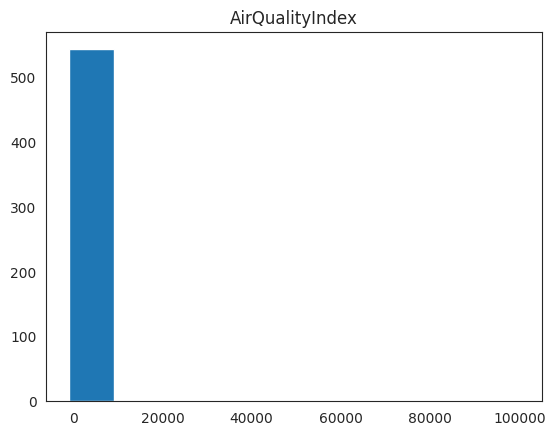

In [ ]:
d8_aqi_skew = plt.hist(df_d["AirQualityIndex"].dropna()); plt.title("AirQualityIndex"); plt.show()
# YOUR CODE HERE
d8_aqi_skew = "right-skewed"


In [ ]:
grader.check_text("D4c_aqi_skew", d8_aqi_skew, ANSWER_KEY["D4c_aqi_skew"], points=2,
                   correct_msg="Correct - the sensor-glitch readings (e.g. 50000) create an extreme right tail.",
                   wrong_msg="Compute df_d['AirQualityIndex'].dropna().skew() directly.")


✅ [D4c_aqi_skew] Correct - the sensor-glitch readings (e.g. 50000) create an extreme right tail.  (+2/2 pts)


True

### Question D9 — Countplot & class imbalance

Draw a countplot of the raw `Location` column. Which single string value
appears **most frequently**? Store it (matching its exact raw
capitalization) in `d9_majority_location`.


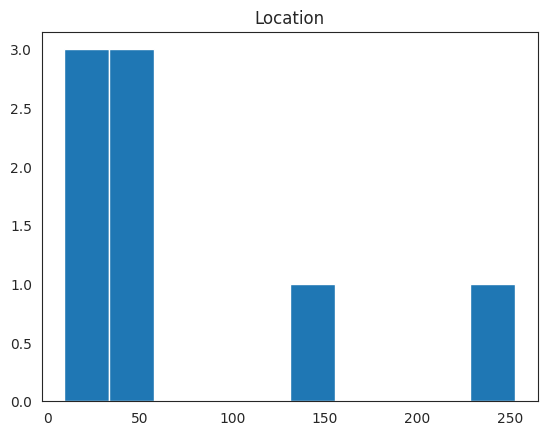

Location
Indoor      253
Outdoor     143
Indoor       42
INDOOR       41
indoor       38
outdoor      25
OUTDOOR      16
Out Door      9
Name: count, dtype: int64


In [ ]:
d9_majority_location = plt.hist(df_d["Location"].value_counts()); plt.title("Location"); plt.show()
d9_majority_location = df_d["Location"].value_counts()
print(d9_majority_location)
# YOUR CODE HERE
d9_majority_location = "Indoor"


In [ ]:
grader.check_text("D4d_location_majority", d9_majority_location, ANSWER_KEY["D4d_location_majority"], points=1,
                   correct_msg="Correct.",
                   wrong_msg="Check df_d['Location'].value_counts().")


✅ [D4d_location_majority] Correct.  (+1/1 pts)


True

### Question D10 — Scatter plot & correlation direction

Scatter-plot `AirQualityIndex` against `SymptomScore`. Store your
interpretation in `d10_direction`.

⚠️ Three rows have wildly implausible `AirQualityIndex` sensor readings
(e.g. `50000`, `-999`). Think about whether you should filter those out
*before* judging the overall pattern, the same way we discussed extreme
values earlier in the course.


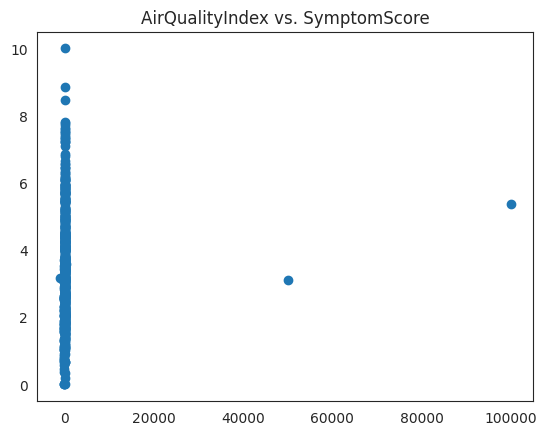

In [ ]:
d10_direction = plt.scatter(x=df_d["AirQualityIndex"], y=df_d["SymptomScore"]); plt.title("AirQualityIndex vs. SymptomScore"); plt.show()
# YOUR CODE HERE
d10_direction = "positive"


In [ ]:
grader.check_text("D5_corr_aqi_symptom", d10_direction, ANSWER_KEY["D5_corr_aqi_symptom"], points=2,
                   correct_msg="Correct - worse air quality is associated with higher self-reported symptoms.",
                   wrong_msg="Try filtering out the impossible sensor readings first, then look at the scatter plot again.")


✅ [D5_corr_aqi_symptom] Correct - worse air quality is associated with higher self-reported symptoms.  (+2/2 pts)


True

### Question D11 — A weaker relationship

Scatter-plot `HeartRate_bpm` against `SymptomScore`. Store your
interpretation in `d11_direction`.


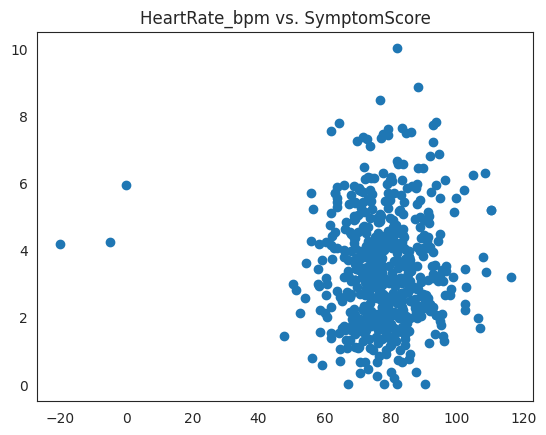

In [ ]:
d11_direction = plt.scatter(x=df_d["HeartRate_bpm"], y=df_d["SymptomScore"]); plt.title("HeartRate_bpm vs. SymptomScore"); plt.show()
# YOUR CODE HERE
d11_direction = "none"


In [ ]:
grader.check_text("D6_corr_hr_symptom", d11_direction, ANSWER_KEY["D6_corr_hr_symptom"], points=2,
                   correct_msg="Correct.",
                   wrong_msg="Compare the spread here to the AirQualityIndex scatter plot in D10.")


✅ [D6_corr_hr_symptom] Correct.  (+2/2 pts)


True

### Question D12 — Correlation heatmap (multivariate view)

Build a Spearman correlation matrix across `Temperature_C`, `Humidity_pct`,
`AirQualityIndex`, `HeartRate_bpm`, and `SymptomScore`, and plot it as a
heatmap. Which two columns are **most strongly** correlated? Store both
names as a list of two strings in `d12_strongest_pair`.


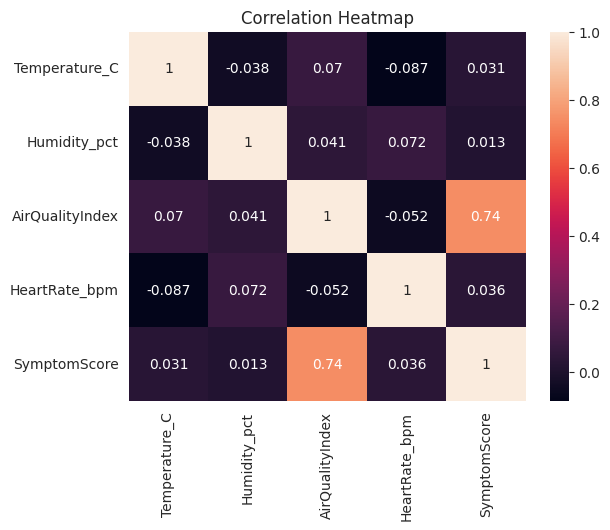

frozenset({'SymptomScore', 'AirQualityIndex'})


In [ ]:
sns.heatmap(df_d[["Temperature_C", "Humidity_pct", "AirQualityIndex", "HeartRate_bpm", "SymptomScore"]].corr(method="spearman"), annot=True); plt.title("Correlation Heatmap"); plt.show()
d12_strongest_pair = _strongest_pair(df_d[["Temperature_C", "Humidity_pct", "AirQualityIndex", "HeartRate_bpm", "SymptomScore"]].corr(method="spearman"))
print(d12_strongest_pair)
# YOUR CODE HERE
d12_strongest_pair = ["AirQualityIndex", "SymptomScore"]


In [ ]:
grader.check_set("D6b_strongest_pair", d12_strongest_pair, ANSWER_KEY["D6b_strongest_pair"], points=2,
                  correct_msg="Correct.",
                  wrong_msg="Look for the darkest off-diagonal cell in the heatmap (by absolute value).")


✅ [D6b_strongest_pair] Correct.  (+2/2 pts)


True

### Question D13 — Grouped comparison

Clean the `Location` spelling (strip + lowercase), then find which cleaned
location has the **higher mean `SymptomScore`**. Store the cleaned location
name (lowercase) in `d13_top_location`.


In [ ]:
d13_top_location = df_d.assign(_clean_loc=df_d["Location"].astype(str).str.strip().str.lower())\
                        .groupby("_clean_loc")["SymptomScore"].mean().idxmax()
print(d13_top_location)
# YOUR CODE HERE
d13_top_location = "out door"


indoor


In [ ]:
grader.check_text("D7_top_location", d13_top_location, ANSWER_KEY["D7_top_location"], points=2,
                   correct_msg="Correct.",
                   wrong_msg="Make sure Location spelling was cleaned before grouping.")


❌ [D7_top_location] Make sure Location spelling was cleaned before grouping.  (+0/2 pts)


False

### Question D14 — Outlier reasoning (short answer, not auto-graded)

One row has `AirQualityIndex = 50000`, another `-999`. Separately, one row
has a genuine `AirQualityIndex` of `310` (a real bad-air day). Explain, in
2-3 sentences, how you would tell these apart using only the data in front
of you — what would make `310` believable where `50000` is not?

*(Not auto-graded — a human will read this.)*


Run the cell below for your Section D score.


In [ ]:
grader.section_summary("D")



Section D score: 13/20 points (9/14 questions correct)


(13, 20)

---
# Final Score Summary

Run the cell below **once you've attempted every section** (A, B, C, D).
It aggregates every question you've answered so far into one final score
out of the total available points, and lists which question IDs still need
review.


In [ ]:
grader.final_summary()


FINAL SCORE: 65/83 points (78.3%)
Questions correct: 46/59
Questions to review: A2_missing, B2_missing, B2b_total_missing, B5b_revenue_outliers, B8_top_category, C2_missing, C2b_total_missing, C5b_price_outliers, D2_missing, D2b_total_missing, D4_impossible_humidity, D4b_aqi_outliers, D7_top_location


(65, 83)

### 🖼️ Schematic — reading an IQR box, for your outlier reasoning answers

```
                lower                                upper
                bound        Q1      median    Q3    bound
                  │           │         │        │      │
      outliers    │           ▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓      │    outliers
   o   o     o ───┼───────────┫       │        ┣──────────┼─── o    o
                  │           ▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓      │
                  │                                      │
             Q1 − 1.5×IQR                          Q3 + 1.5×IQR
```

Anything beyond the whiskers is a **candidate** outlier flagged by the IQR
rule — not an automatic error. Every "outlier reasoning" question in this
test (A9, B9, C9, D8) asks you to look at the *whole row*, not just the one
flagged number, before deciding whether to trust it.

---

## What this test covered

Across all four sections you practiced the same loop, on four different
kinds of real-world data:

- **Profiling** — shape, dtypes, missing values, duplicates
- **Diagnosing** — impossible values, inconsistent category spelling,
  numbers stored as text
- **Univariate & outlier reasoning** — telling a data-entry error apart
  from a genuine extreme value
- **Bivariate analysis** — reading a scatter plot's direction (positive /
  negative / none), grouped comparisons
- **The core reminder from the lecture:** *"An outlier is not automatically
  an error,"* and *"correlation does not automatically mean causation."*

If any question above still shows ❌, scroll back up, re-read the hint in
that question, and try again — the goal of this test is that you leave it
being able to do this on **any** new dataset, not just these four.
